# 🌿 Deep Analysis — Dashboard Analysis Gelar Rasa 2026
**Kualitas Udara & Kesehatan Masyarakat di 27 Wilayah Indonesia (2024 – 14 Okt 2026)**

Notebook ini adalah fondasi analisis untuk dashboard dan laporan. Isinya:

1. **Perbaikan format & kualitas data**: satuan, timestamp, flag QC, sentinel, sensor beku, resolusi campur, dll.
2. **Analisis mendalam** untuk 6 pertanyaan analisis (Q1–Q6).
3. **Pemodelan**: tipologi stasiun (clustering), pemicu variasi (LightGBM + SHAP), dampak kesehatan (Poisson dua tahap + LightGBM), deteksi anomali.
4. **Simulasi dampak kesehatan**: "kalau PM2.5 jadi X, kasus naik/turun berapa?"
5. **Evaluasi**: apakah insight yang didapat sudah menjawab tiap pertanyaan.

> Semua analisis hanya memakai dataset panitia. Acuan regulasi (PP 22/2021, Permen LHK 14/2020) dan pedoman WHO 2021 dipakai sebagai pembanding, bukan dataset tambahan.

## 📌 Ringkasan Eksekutif

**Big idea yang didukung data: "Dua krisis udara, satu sistem yang belum siap."**

| # | Temuan | Angka kunci |
|---|---|---|
| 1 | **Hampir semua wilayah melampaui baku mutu tahunan**, dan makin banyak yang bahkan gagal target WHO paling longgar | 21 dari 24 stasiun > 15 µg/m³ · gagal IT-1 (35): **12 → 16** stasiun (2024 → 2025) · PM2.5 pencemar kritis di **99,6%** hari |
| 2 | **Dua jenis krisis**: kronis (tinggi & stabil, mis. Marunda 100% hari > 55) vs episodik (asap musiman), terbukti dari clustering pola waktu | 10 stasiun episodik, 8 kronis, 4 sedang, 3 latar bersih |
| 3 | **Memburuk terutama di gambut, dan hanya saat musim asap** | Gambut **+102%**, non-gambut +3% (1 Jan–14 Okt 2024→2026). Kalteng: Jul–Okt **+540%**, Jan–Jun datar. Puncak bulanan gambut 69,6 → 108,0 → **335,6** µg/m³. Pengecualian: **Samarinda** justru memburuk di luar musim asap (Jan–Jun **+61%**) |
| 4 | **Musim menentukan, bukan cuaca harian** | Musim/episode 82% variasi, lokasi 16%; cuaca hanya ±14% kontribusi model; arah angin tidak berpengaruh (beda 0–6%) |
| 5 | **Dampak kesehatan besar dan langsung (hari yang sama)** | PM2.5 berlipat dua → ISPA balita **+56%**, kematian **+27%**; tidak ada efek tertunda (lag 1–3 & plasebo ≈ 1); stabil di 8 uji sensitivitas |
| 6 | **Kardiovaskular & kematian punya ambang 150 µg/m³** | Di atas ambang, risiko naik tambahan +18% (kardiovaskular) dan +14% (kematian) per +100 µg/m³ |
| 7 | **Simulasi:** patuh baku mutu harian (55) di 25 RS pada 2025 | ≈ **−5.973 ISPA balita, −6.661 ISPA lansia, −695 kematian** |
| 8 | **Sistem pemantau belum siap** | 2 stasiun rusak tersembunyi (status *Active*), 4 bermasalah yang diakui, 1 pasangan kembar, 1 pasangan berdempetan 0,9 km. **IKU resmi "buta asap"**: 12 stasiun ber-IKU *Baik* padahal PM2.5-nya gagal target WHO IT-1 |

**Model:** simulasi memakai model statistik dua tahap (Poisson log-PM per RS + meta-analisis, ditambah model ambang untuk kardiovaskular & kematian), karena di uji 2026 model ini mengalahkan LightGBM, terutama pada hari asap ekstrem di luar rentang data latih (R² 0,81 vs 0,44).

> Detail jawaban per pertanyaan dan status ada di **Bagian 8**. Tabel ISPU dan rumus IKU diverifikasi langsung dari dokumen resmi Permen LHK 14/2020 dan 27/2021.

---
## 0. Setup

In [1]:
import warnings, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lightgbm as lgb
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, mean_poisson_deviance, mean_absolute_error, r2_score
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
try:
    display
except NameError:  # saat dijalankan sebagai script biasa
    display = print

ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent
RAW = ROOT / "Dataset"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "analysis" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})
ISPU_LAB = ["Baik", "Sedang", "Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"]
ISPU_COL = ["#2e9d3a", "#2f6fd6", "#f2c40f", "#d62728", "#1b1b1b"]
PM25_BINS = [-np.inf, 15.5, 55.4, 150.4, 250.4, np.inf]   # batas konsentrasi PM2.5 per kategori ISPU (24 jam)
KELOMPOK_COL = {"Gambut": "#b5542c", "Industri": "#6a4c93", "Roadside": "#e07a1f",
                "Urban": "#4a6fa5", "Pesisir": "#2a9d8f", "Latar Bersih": "#7fb069"}

def savefig(name):
    plt.savefig(FIG / f"{name}.png")
    plt.show()

def fmt(v, d=1):
    """Format angka gaya Indonesia (koma desimal)."""
    return f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

print("ROOT:", ROOT)

ROOT: D:\Lomba\Gelar Rasa 2026


### Tabel master & peta stasiun ↔ rumah sakit
Tidak ada kolom penghubung RS ↔ stasiun di data. Pemetaan diambil dari tabel bagian E booklet: `SENS-0NN` ↔ `RS-XXX-NN`. Di bawah ini dicek bahwa provinsi dan kecamatannya memang cocok.

In [2]:
sites = pd.read_csv(RAW / "sites.csv")
sensors = pd.read_csv(RAW / "sensors.csv")
hospitals = pd.read_csv(RAW / "hospitals.csv")
meta_sensors = pd.read_csv(RAW / "metadata" / "metadata_sensors.csv")
meta_dates = pd.read_csv(RAW / "metadata" / "metadata_dates.csv")

sites["code"] = sites["location_id"].str.replace("LOC-", "", regex=False)
sensors["code"] = sensors["location_id"].str.replace("LOC-", "", regex=False)
sensors["hospital_id"] = "RS-XXX-" + sensors["sensor_id"].str[-2:]

PULAU = {"JKT": "Jawa", "BGR": "Jawa", "YKY": "Jawa", "MLG": "Jawa",
         "KTG": "Kalimantan", "STG": "Kalimantan", "PKN": "Kalimantan", "SM2": "Kalimantan", "BJB": "Kalimantan",
         "MRS": "Sulawesi", "PLU": "Sulawesi", "SRG": "Papua", "MER": "Papua"}
TZ_OFFSET = {"SM2-01": 1, "BJB-01": 1, "MRS-01": 1, "PLU-01": 1, "SRG-01": 2, "MER-01": 2}  # WITA +1, WIT +2

def kelompok(row):
    st, kar = row["site_type"], row["karakteristik_wilayah"]
    if "Peat" in st or "ambut" in kar: return "Gambut"
    if "Clean Background" in st: return "Latar Bersih"
    if "Industrial" in st: return "Industri"
    if "Traffic" in st: return "Roadside"
    if "Coastal" in st: return "Pesisir"
    return "Urban"

st = sites.merge(sensors[["code", "sensor_id", "hospital_id", "status_operasional", "tanggal_instalasi"]], on="code")
st["pulau"] = st["code"].str[:3].map(PULAU).fillna("Sumatera")
st["kelompok"] = st.apply(kelompok, axis=1)
st["gambut"] = np.where(st["kelompok"] == "Gambut", "Gambut", "Non-gambut")
st["tz_offset"] = st["code"].map(TZ_OFFSET).fillna(0).astype(int)
st["nama"] = st["kecamatan"].str.replace(r"\s*\(.*\)", "", regex=True)
st = st.merge(hospitals[["hospital_id", "provinsi", "kecamatan", "kelas_faskes", "kapasitas_tempat_tidur"]]
              .rename(columns={"provinsi": "provinsi_rs", "kecamatan": "kecamatan_rs"}), on="hospital_id")
cek = (st["provinsi"] == st["provinsi_rs"]) & (st["kecamatan"].str[:6] == st["kecamatan_rs"].str[:6])
print(f"Pasangan stasiun-RS yang provinsi & kecamatannya cocok: {cek.sum()} dari {len(st)}")
display(st[["code", "provinsi", "kecamatan", "pulau", "kelompok", "site_type", "status_operasional", "hospital_id", "kelas_faskes", "kapasitas_tempat_tidur"]])

Pasangan stasiun-RS yang provinsi & kecamatannya cocok: 27 dari 27


,code,provinsi,kecamatan,pulau,kelompok,site_type,status_operasional,hospital_id,kelas_faskes,kapasitas_tempat_tidur
0,JKT-01,DKI Jakarta,Gambir,Jawa,Urban,Urban Background,Active,RS-XXX-01,Tipe B,300.00
1,JKT-02,DKI Jakarta,Cilincing (Marunda),Jawa,Industri,Industrial Perimeter,Active,RS-XXX-02,Tipe B,250.00
2,JKT-03,DKI Jakarta,Cengkareng,Jawa,Roadside,Traffic / Roadside,Active,RS-XXX-03,Tipe B,280.00
3,KTG-01,Kalimantan Tengah,Jekan Raya,Kalimantan,Gambut,Urban Background,Active,RS-XXX-04,Tipe B,220.00
4,KTG-02,Kalimantan Tengah,Mentawa Baru Ketapang (Sampit),Kalimantan,Gambut,Peatland Boundary,Active,RS-XXX-05,Tipe C,150.00
5,BGR-01,Jawa Barat,Cisarua,Jawa,Latar Bersih,Regional / Clean Background,Active,RS-XXX-06,Tipe A (Khusus Paru),200.00
6,BGR-02,Jawa Barat,Bogor Tengah (Baranangsiang),Jawa,Roadside,Traffic / Roadside,Active,RS-XXX-07,Tipe B,260.00
7,YKY-01,D.I. Yogyakarta,Mlati,Jawa,Urban,Urban Background,Active,RS-XXX-08,Tipe B,250.00
8,IDP-01,Aceh,Indrapuri,Sumatera,Latar Bersih,Regional / Clean Background,Active,RS-XXX-09,Tipe C,120.00
9,KTB-01,Sumatera Barat,Palembayan,Sumatera,Latar Bersih,Regional / Clean Background,Active,RS-XXX-10,Tipe B,180.00


---
## 1. Perbaikan Format & Kualitas Data

Hasil dua audit tim (5–6 Nov) yang sudah dicek silang. Masalah yang ditangani:

| Masalah | Stasiun | Penanganan |
|---|---|---|
| Satuan ppm | BJB-01, MDN-01, PSW-01 | Gas → µg/m³ (25 °C, 1 atm). PM ×1000 (**asumsi**, dicek ke `baseline_pm25`) |
| Teks di kolom angka (`0xDEADBEEF`, `#VALUE!`, ...) & `inf` | JMB-02 | → NaN |
| Sentinel numerik | JMB-02 (−9999 s.d. 100000), SM2-01 (999) | → NaN, **ditentukan per stasiun** |
| Timestamp 1970 & durasi negatif | JMB-02 | Baris dibuang |
| Clock offset | Banyak stasiun | Dibulatkan **ke bawah** (`floor`) ke jam |
| Flag QC 12 nilai | Semua | Hanya VALID, + SUSPECT jika statistiknya setara VALID (diuji per stasiun) |
| Nilai fisik mustahil | MER-01, JMB-02 | Negatif, PM2.5 > PM10, RH > 100%, arah angin > 360°, suhu di luar 5–45 °C → NaN |
| Sensor beku berlabel VALID | BJB-01 | *Run* nilai konstan ≥ 24 jam → NaN |
| Resolusi 15 menit | PLB-01 (Sep–Okt) | Dirata-rata per jam |
| Jam hilang | MDN-01 | Reindex ke grid per jam, celah ≤ 3 jam diinterpolasi |

In [3]:
POLL = ["pm25", "pm10", "so2", "co", "o3", "no2"]
MET = ["temperature_c", "humidity_pct", "wind_speed_ms", "wind_direction_deg"]
MW = {"so2": 64.066, "co": 28.01, "o3": 48.00, "no2": 46.0055}
SENT_UNIVERSAL = {-9999.0, -999.0, 9999.0, 8888.0, 100000.0, -273.2}
SENT_STATION = {
    "JMB-02": {-9999, -999, -99, -50, -40, 999, 999.9, 9999, 8888, 100000, -150, -99.9, -273.2, 850, 1450.5, 350},
    "SM2-01": {999.0},
}
STATUS = dict(zip(st.code, st.status_operasional))
GRID = pd.date_range("2023-12-31 23:00", "2026-10-14 23:00", freq="h")
EXPECTED_H = 24432

def frozen_mask(v, minrun=24):
    """True untuk nilai yang sama persis berturut-turut minimal `minrun` kali (sensor beku)."""
    run = (v != v.shift()).cumsum()
    return v.notna() & (v.groupby(run).transform("size") >= minrun)

def fill_short_gaps(s, maxlen=3):
    """Interpolasi linear hanya untuk celah NaN sepanjang <= maxlen jam."""
    na = s.isna()
    if not na.any():
        return s, 0
    run = (na != na.shift()).cumsum()
    fillable = na & (na.groupby(run).transform("size") <= maxlen)
    out = s.copy()
    out[fillable] = s.interpolate(limit_area="inside")[fillable]
    return out, int(out[fillable].notna().sum())

def clean_station(path):
    code = path.name.split("_")[0]
    d = pd.read_csv(path, dtype=str, keep_default_na=False)
    lg = {"stasiun": code, "status_metadata": STATUS.get(code), "baris_mentah": len(d)}
    src = {p: (f"{p}_ug_m3" if f"{p}_ug_m3" in d.columns else f"{p}_ppm") for p in POLL}
    lg["satuan_asli"] = "ppm" if src["pm25"].endswith("_ppm") else "µg/m³"
    cols = list(src.values()) + MET
    raw = d[cols].apply(lambda c: c.str.strip())
    num = raw.apply(pd.to_numeric, errors="coerce")
    lg["sel_teks_error"] = int(((raw != "") & num.isna()).sum().sum())
    isinf = np.isinf(num)
    lg["sel_inf"] = int(isinf.sum().sum())
    num = num.mask(isinf)
    sent = SENT_UNIVERSAL | SENT_STATION.get(code, set())
    is_sent = num.isin(list(sent))
    lg["sel_sentinel"] = int(is_sent.sum().sum())
    num = num.mask(is_sent)
    x = pd.DataFrame(index=d.index)
    for p in POLL:
        v = num[src[p]]
        if src[p].endswith("_ppm"):
            v = v * (1000 if p in ("pm25", "pm10") else MW[p] * 1000 / 24.45)
        x[p] = v
    for m in MET:
        x[m] = num[m]
    ts = pd.to_datetime(d["timestamp_start"], errors="coerce", format="mixed")
    te = pd.to_datetime(d["timestamp_end"], errors="coerce", format="mixed")
    bad_ts = ts.isna() | (ts < pd.Timestamp("2023-12-31"))
    neg = ~bad_ts & ((te - ts) <= pd.Timedelta(0))
    lg["baris_timestamp_rusak"] = int(bad_ts.sum())
    lg["baris_durasi_negatif"] = int(neg.sum())
    keep = ~(bad_ts | neg)
    qc = d["qc_flag"].str.strip().str.upper()
    pm_tmp = x["pm25"].where(x["pm25"] >= 0)
    med_v = pm_tmp[keep & (qc == "VALID")].median()
    med_s = pm_tmp[keep & (qc == "SUSPECT")].median()
    ratio = med_s / med_v if (pd.notna(med_s) and pd.notna(med_v) and med_v > 0) else np.nan
    keep_susp = bool(pd.notna(ratio) and 0.85 <= ratio <= 1.15)
    lg["rasio_median_SUSPECT/VALID"] = round(float(ratio), 2) if pd.notna(ratio) else np.nan
    lg["SUSPECT_dipakai"] = keep_susp
    ok_flags = {"VALID"} | ({"SUSPECT"} if keep_susp else set())
    drop_qc = keep & ~qc.isin(ok_flags)
    lg["baris_dibuang_qc"] = int(drop_qc.sum())
    keep &= ~drop_qc
    x = x[keep].copy()
    x["ts"] = ts[keep].dt.floor("h")
    n_phys = 0
    for p in POLL:
        m = x[p] < 0
        n_phys += int(m.sum()); x.loc[m, p] = np.nan
    m = x["pm25"] > x["pm10"]
    lg["baris_pm25>pm10"] = int(m.sum()); x.loc[m, ["pm25", "pm10"]] = np.nan
    for c, (lo, hi) in {"humidity_pct": (0, 100), "wind_direction_deg": (0, 360),
                        "wind_speed_ms": (0, 60), "temperature_c": (5, 45)}.items():
        m = (x[c] < lo) | (x[c] > hi)
        n_phys += int(m.sum()); x.loc[m, c] = np.nan
    lg["sel_fisik_mustahil"] = n_phys
    x = x.sort_values("ts")
    fz = frozen_mask(x["pm25"])
    lg["baris_sensor_beku"] = int(fz.sum())
    x.loc[fz, POLL] = np.nan
    x["wd_sin"] = np.sin(np.radians(x["wind_direction_deg"]))
    x["wd_cos"] = np.cos(np.radians(x["wind_direction_deg"]))
    num_cols = POLL + ["temperature_c", "humidity_pct", "wind_speed_ms", "wd_sin", "wd_cos"]
    h = x.groupby("ts")[num_cols].mean()
    lg["jam_terisi_sebelum_reindex"] = len(h)
    h = h.reindex(GRID)
    for c in num_cols:
        h[c], nfill = fill_short_gaps(h[c], 3)
        if c == "pm25":
            lg["jam_pm25_diinterpolasi"] = nfill
    h["wind_direction_deg"] = np.degrees(np.arctan2(h["wd_sin"], h["wd_cos"])) % 360
    h = h.drop(columns=["wd_sin", "wd_cos"])
    lg["jam_pm25_valid_akhir"] = int(h["pm25"].notna().sum())
    lg["cakupan_pm25_%"] = round(100 * lg["jam_pm25_valid_akhir"] / EXPECTED_H, 1)
    h["code"] = code
    return h.rename_axis("ts").reset_index(), lg

frames, logs = [], []
for f in sorted(RAW.glob("*_AQMS.csv")):
    h, lg = clean_station(f)
    frames.append(h); logs.append(lg)
hourly = pd.concat(frames, ignore_index=True)
clean_log = pd.DataFrame(logs).set_index("stasiun")
clean_log.to_csv(OUT / "cleaning_log.csv")
display(clean_log)

,status_metadata,baris_mentah,satuan_asli,sel_teks_error,sel_inf,sel_sentinel,baris_timestamp_rusak,baris_durasi_negatif,rasio_median_SUSPECT/VALID,SUSPECT_dipakai,baris_dibuang_qc,baris_pm25>pm10,sel_fisik_mustahil,baris_sensor_beku,jam_terisi_sebelum_reindex,jam_pm25_diinterpolasi,jam_pm25_valid_akhir,cakupan_pm25_%
stasiun,,,,,,,,,,,,,,,,,,
BGL-01,Active,24432,µg/m³,0,0,0,0,0,1.03,True,0,0,0,0,24432,0,24432,100.00
BGR-01,Active,24432,µg/m³,0,0,0,0,0,1.00,True,256,0,0,0,24176,256,24432,100.00
BGR-02,Active,24432,µg/m³,0,0,0,0,0,1.02,True,253,0,0,0,24179,253,24432,100.00
BJB-01,Active,24432,ppm,0,0,0,0,0,NaN,False,0,0,0,7329,24432,0,17103,70.00
BTM-01,Active,24432,µg/m³,0,0,0,0,0,1.00,True,0,0,0,0,24432,0,24432,100.00
IDP-01,Active,24432,µg/m³,0,0,0,0,0,1.02,True,0,0,0,0,24432,0,24432,100.00
JKT-01,Active,24432,µg/m³,0,0,0,0,0,1.00,True,367,0,0,0,24065,367,24432,100.00
JKT-02,Active,24432,µg/m³,0,0,0,0,0,0.99,True,343,0,0,0,24089,343,24432,100.00
JKT-03,Active,24432,µg/m³,0,0,0,0,0,0.99,True,366,0,0,0,24066,366,24432,100.00


**Cek konversi PM dari ppm (×1000).** Kalau asumsinya benar, rata-rata PM2.5 hasil konversi di 3 stasiun ppm seharusnya dekat dengan `baseline_pm25` di `sites.csv`, sebanding dengan stasiun µg/m³ lainnya.

In [4]:
base = hourly.groupby("code")["pm25"].median().rename("median_pm25_bersih").to_frame()
base = base.join(st.set_index("code")[["baseline_pm25"]])
base["rasio_terhadap_baseline"] = base["median_pm25_bersih"] / base["baseline_pm25"]
base["satuan_asli"] = clean_log["satuan_asli"]
display(base.groupby("satuan_asli")["rasio_terhadap_baseline"].describe()[["count", "mean", "min", "max"]])
display(base[base.satuan_asli == "ppm"])

,count,mean,min,max
satuan_asli,,,,
ppm,3.00,1.03,0.80,1.22
µg/m³,24.00,1.03,0.71,1.50


,median_pm25_bersih,baseline_pm25,rasio_terhadap_baseline,satuan_asli
code,,,,
BJB-01,42.60,35.00,1.22,ppm
MDN-01,46.45,42.80,1.09,ppm
PSW-01,43.50,54.30,0.80,ppm


### Agregasi harian, waktu lokal, dan data kesehatan
- **Rata-rata harian** hanya dihitung jika ada **≥ 18 jam valid (75%)**.
- **Jam lokal** untuk analisis pola harian: WITA +1, WIT +2 jam dari WIB.
- **JMB-02** dikeluarkan dari analisis polutan (rusak total), tetapi tetap dibahas di analisis jaringan.
- **MER-01** hanya punya ±10 hari yang memenuhi syarat 75% (jam valid tersebar acak), sehingga dikeluarkan dari statistik per stasiun dan dibahas di analisis jaringan.

In [5]:
hourly["ts_local"] = hourly["ts"] + pd.to_timedelta(hourly["code"].map(TZ_OFFSET).fillna(0), unit="h")
hourly["date"] = hourly["ts"].dt.normalize()
VALS = POLL + ["temperature_c", "humidity_pct", "wind_speed_ms"]
g = hourly.groupby(["code", "date"])[VALS]
daily = g.mean().where(g.count() >= 18).reset_index()
daily = daily.merge(st[["code", "pulau", "kelompok", "gambut", "hospital_id"]], on="code")
daily["tahun"] = daily["date"].dt.year
daily["bulan"] = daily["date"].dt.month
daily["md"] = daily["date"].dt.strftime("%m-%d")
EXCL = ["JMB-02"]          # rusak total: dikeluarkan dari semua analisis polutan
LOWCOV = ["MER-01"]        # hari valid terlalu sedikit: dikeluarkan dari statistik per stasiun
D = daily[~daily.code.isin(EXCL) & (daily.date >= "2024-01-01")].copy()
print("Hari valid per stasiun (rata-rata harian sah):", D.groupby("code").pm25.count().sort_values().head(4).to_dict())
hourly.to_parquet(OUT / "aqms_hourly_clean.parquet", index=False)
daily.to_parquet(OUT / "aqms_daily_clean.parquet", index=False)

hl = pd.read_csv(RAW / "HLT-01_health_outcomes_daily.csv", parse_dates=["date"])
OUTC = ["resp_admissions_under5", "resp_admissions_over60", "asthma_emergency_cases",
        "copd_admissions", "resp", "cvd", "death"]
OUTC_LAB = {"resp_admissions_under5": "ISPA balita", "resp_admissions_over60": "ISPA lansia",
            "asthma_emergency_cases": "Darurat asma", "copd_admissions": "PPOK", "resp": "Rawat napas umum",
            "cvd": "Kardiovaskular", "death": "Kematian"}
print("Duplikat RS-tanggal:", hl.duplicated(["hospital_id", "date"]).sum(),
      "| nama hari tidak cocok:", (hl.date.dt.day_name() != hl.dow).sum(),
      "| nilai negatif:", (hl[OUTC] < 0).sum().sum())
first = hl.groupby("hospital_id").date.min()
print("RS yang punya baris 31 Des 2023:", list(first[first == "2023-12-31"].index))
off = st[st.hospital_id.isin(first[first == "2023-12-31"].index)].code.tolist()
print("Stasiun pasangannya:", off, "→ cocok dengan stasiun yang timestamp pertamanya 31 Des 23:xx (alasan memakai floor).")
hl = hl.merge(st[["hospital_id", "code", "kelompok", "gambut", "pulau", "kelas_faskes", "kapasitas_tempat_tidur"]], on="hospital_id")
print("Baris kesehatan:", len(hl), "| RS:", hl.hospital_id.nunique())

Hari valid per stasiun (rata-rata harian sah): {'MER-01': 10, 'BJB-01': 712, 'SM2-01': 889, 'MDN-01': 990}


Duplikat RS-tanggal: 0 | nama hari tidak cocok: 0 | nilai negatif: 0
RS yang punya baris 31 Des 2023: ['RS-XXX-12', 'RS-XXX-13', 'RS-XXX-16', 'RS-XXX-19', 'RS-XXX-20']
Stasiun pasangannya: ['JMB-01', 'BTM-01', 'MLG-01', 'STG-01', 'PKN-01'] → cocok dengan stasiun yang timestamp pertamanya 31 Des 23:xx (alasan memakai floor).
Baris kesehatan: 27491 | RS: 27


**Ringkasan dampak pembersihan.** Cakupan PM2.5 per stasiun setelah dibersihkan, dibandingkan dengan status di metadata `sensors.csv`.

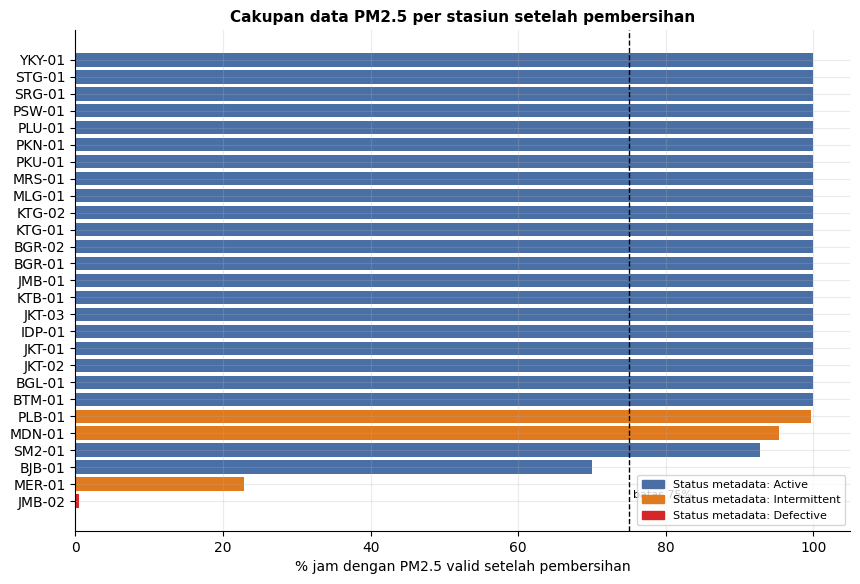

In [6]:
cov = clean_log[["status_metadata", "cakupan_pm25_%"]].sort_values("cakupan_pm25_%")
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = cov["status_metadata"].map({"Active": "#4a6fa5", "Intermittent": "#e07a1f", "Defective": "#d62728"})
ax.barh(cov.index, cov["cakupan_pm25_%"], color=colors)
ax.axvline(75, color="k", ls="--", lw=1)
ax.text(75.5, 0.2, "batas 75%", fontsize=8)
ax.legend(handles=[mpl.patches.Patch(color=c, label=f"Status metadata: {s}") for s, c in
                   {"Active": "#4a6fa5", "Intermittent": "#e07a1f", "Defective": "#d62728"}.items()], loc="lower right", fontsize=8)
ax.set_xlabel("% jam dengan PM2.5 valid setelah pembersihan")
ax.set_title("Cakupan data PM2.5 per stasiun setelah pembersihan")
savefig("01_cakupan_data")

---
## 2. Q1 · Kondisi Kualitas Udara
**Pertanyaan:** Bagaimana kondisi kualitas udara antar stasiun dan pulau terhadap baku mutu nasional, ISPU, dan pedoman WHO, dan bagaimana trennya 2024–2026?

Acuan yang dipakai:
- **PP 22/2021:** PM2.5 rata-rata 24 jam 55 µg/m³, tahunan 15 µg/m³.
- **WHO 2021:** pedoman tahunan PM2.5 5 µg/m³, dengan target antara (*interim target*) IT-1 35 · IT-2 25 · IT-3 15 · IT-4 10.
- **ISPU (Permen LHK 14/2020):** kategori harian dari PM2.5 dan PM10. Batas konsentrasi yang dipakai perlu dicek ulang ke dokumen resmi.

,rata2_pm25,p95_pm25,hari_valid,pct_hari_gt55,pct_hari_gt15,hari_gt150,kelompok,pulau
code,,,,,,,,
SM2-01,80.29,234.91,889,25.20,100.00,203,Industri,Kalimantan
PLB-01,65.58,174.91,1016,27.07,100.00,107,Gambut,Sumatera
KTG-02,61.06,126.05,1018,25.64,100.00,44,Gambut,Kalimantan
KTG-01,60.99,125.82,1018,24.95,100.00,44,Gambut,Kalimantan
JKT-02,60.06,64.77,1018,100.00,100.00,0,Industri,Jawa
JKT-03,54.05,58.69,1018,34.58,100.00,0,Roadside,Jawa
PSW-01,50.72,95.97,1018,25.64,100.00,0,Urban,Sumatera
BJB-01,49.22,82.20,712,28.65,100.00,0,Gambut,Kalimantan
JKT-01,48.08,52.74,1018,0.00,100.00,0,Urban,Jawa


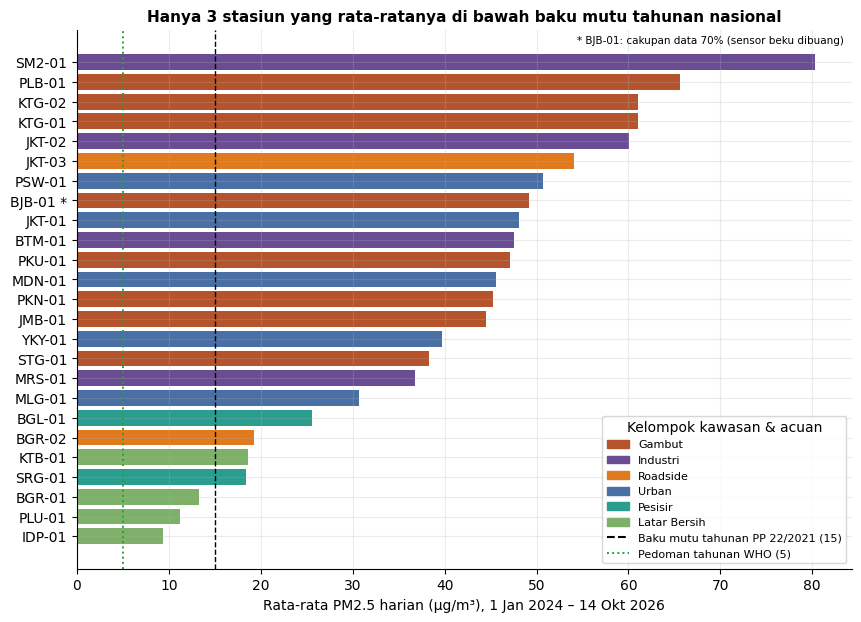

In [7]:
q95 = lambda s: s.quantile(0.95)
summ = D[~D.code.isin(LOWCOV)].groupby("code").agg(
    rata2_pm25=("pm25", "mean"), p95_pm25=("pm25", q95), hari_valid=("pm25", "count"),
    pct_hari_gt55=("pm25", lambda s: 100 * (s.dropna() > 55).mean()),
    pct_hari_gt15=("pm25", lambda s: 100 * (s.dropna() > 15).mean()),
    hari_gt150=("pm25", lambda s: int((s > 150.4).sum())),
).join(st.set_index("code")[["kelompok", "pulau"]]).sort_values("rata2_pm25", ascending=False)
display(summ)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(summ.index[::-1], summ["rata2_pm25"][::-1], color=summ["kelompok"][::-1].map(KELOMPOK_COL))
ax.axvline(15, color="k", ls="--", lw=1)
ax.axvline(5, color="#2e9d3a", ls=":", lw=1.4)
ax.set_yticks(range(len(summ))); ax.set_yticklabels([f"{c}{' *' if c == 'BJB-01' else ''}" for c in summ.index[::-1]])
ax.text(0.99, 0.99, "* BJB-01: cakupan data 70% (sensor beku dibuang)", transform=ax.transAxes, ha="right", va="top", fontsize=7.5)
hdl = [mpl.patches.Patch(color=c, label=k) for k, c in KELOMPOK_COL.items()]
hdl += [mpl.lines.Line2D([], [], color="k", ls="--", label="Baku mutu tahunan PP 22/2021 (15)"),
        mpl.lines.Line2D([], [], color="#2e9d3a", ls=":", lw=1.4, label="Pedoman tahunan WHO (5)")]
ax.legend(handles=hdl, title="Kelompok kawasan & acuan", fontsize=8, loc="lower right")
ax.set_xlabel("Rata-rata PM2.5 harian (µg/m³), 1 Jan 2024 – 14 Okt 2026")
ax.set_title("Hanya 3 stasiun yang rata-ratanya di bawah baku mutu tahunan nasional")
savefig("02_ranking_stasiun")

### Kepatuhan tahunan: baku mutu nasional & tangga target WHO
Rata-rata tahunan hanya sah jika **≥ 75% hari** dalam setahun punya data valid. Karena 2026 baru sampai 14 Oktober, evaluasi tahunan memakai **2024 dan 2025**.

Stasiun yang tidak lolos syarat kelengkapan 75%: ['BJB-01', 'MER-01']
2024: 24 stasiun sah | melampaui baku mutu tahunan nasional: 21 | belum capai IT-1 WHO (>35): 12
2025: 24 stasiun sah | melampaui baku mutu tahunan nasional: 21 | belum capai IT-1 WHO (>35): 16


tahun,2024,2025
tingkat_WHO,,
Belum capai IT-1 (>35),12,16
IT-1 (≤35),6,2
IT-2 (≤25),3,3
IT-3 (≤15),2,2
IT-4 (≤10),1,1
AQG (≤5),0,0


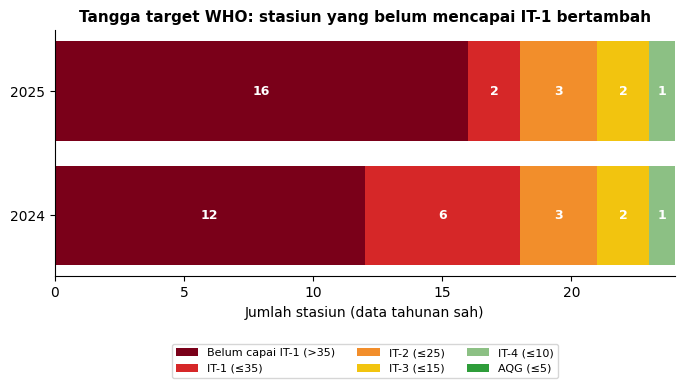

In [8]:
def tingkat_who(v):
    if v <= 5: return "AQG (≤5)"
    if v <= 10: return "IT-4 (≤10)"
    if v <= 15: return "IT-3 (≤15)"
    if v <= 25: return "IT-2 (≤25)"
    if v <= 35: return "IT-1 (≤35)"
    return "Belum capai IT-1 (>35)"

ann = (D[D.tahun.isin([2024, 2025])].groupby(["code", "tahun"])
       .agg(rata2=("pm25", "mean"), hari=("pm25", "count")).reset_index())
ann["lengkap"] = ann["hari"] >= 0.75 * ann["tahun"].map({2024: 366, 2025: 365})
ann["lampaui_PP22"] = ann["rata2"] > 15
ann["tingkat_WHO"] = ann["rata2"].apply(tingkat_who)
A = ann[ann.lengkap]
print("Stasiun yang tidak lolos syarat kelengkapan 75%:", sorted(ann[~ann.lengkap].code.unique()))
for y in [2024, 2025]:
    a = A[A.tahun == y]
    print(f"{y}: {len(a)} stasiun sah | melampaui baku mutu tahunan nasional: {a.lampaui_PP22.sum()} | "
          f"belum capai IT-1 WHO (>35): {(a.rata2 > 35).sum()}")
tier_order = ["Belum capai IT-1 (>35)", "IT-1 (≤35)", "IT-2 (≤25)", "IT-3 (≤15)", "IT-4 (≤10)", "AQG (≤5)"]
tier_tab = pd.crosstab(A["tingkat_WHO"], A["tahun"]).reindex(tier_order).fillna(0).astype(int)
display(tier_tab)

fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(2)
tier_col = ["#7a0019", "#d62728", "#f28e2b", "#f2c40f", "#8cc084", "#2e9d3a"]
for t, c in zip(tier_order, tier_col):
    vals = tier_tab.loc[t].values
    ax.barh(["2024", "2025"], vals, left=left, color=c, label=t)
    for i, v in enumerate(vals):
        if v: ax.text(left[i] + v / 2, i, str(v), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += vals
ax.legend(ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.25), loc="upper center")
ax.set_xlabel("Jumlah stasiun (data tahunan sah)")
ax.set_title("Tangga target WHO: stasiun yang belum mencapai IT-1 bertambah")
ax.grid(False)
savefig("03_tangga_who")

### ISPU harian lengkap & polutan kritis
Tabel konversi resmi **Permen LHK P.14/MENLHK/SETJEN/KUM.1/7/2020, Lampiran I** (diverifikasi langsung dari Berita Negara No. 774/2020). Semua parameter memakai **rata-rata 24 jam**. ISPU harian = sub-indeks tertinggi; parameter dengan sub-indeks tertinggi = **parameter pencemar kritis**. HC tidak diukur di dataset ini.

| ISPU | PM10 | PM2.5 | SO₂ | CO | O₃ | NO₂ |
|---|---|---|---|---|---|---|
| 50 | 50 | 15,5 | 52 | 4.000 | 120 | 80 |
| 100 | 150 | 55,4 | 180 | 8.000 | 235 | 200 |
| 200 | 350 | 150,4 | 400 | 15.000 | 400 | 1.130 |
| 300 | 420 | 250,4 | 800 | 30.000 | 800 | 2.260 |
| 500 | 500 | 500 | 1.200 | 45.000 | 1.000 | 3.000 |

Rumus: I = (Ia − Ib)/(Xa − Xb) × (Xx − Xb) + Ib. Kategori (Lampiran II): Baik 1–50 (hijau), Sedang 51–100 (biru), Tidak Sehat 101–200 (kuning), Sangat Tidak Sehat 201–300 (merah), Berbahaya ≥ 301 (hitam).

Parameter pencemar kritis (share hari-stasiun): {'PM2.5': 99.6, 'PM10': 0.4}
Hari ketika gas menjadi pencemar kritis: 0 dari 24995 hari-stasiun {}
ISPU tertinggi yang pernah dicapai tiap gas: {'SO₂': 33, 'CO': 95, 'O₃': 19, 'NO₂': 42} → tidak ada gas yang mencapai kategori Tidak Sehat


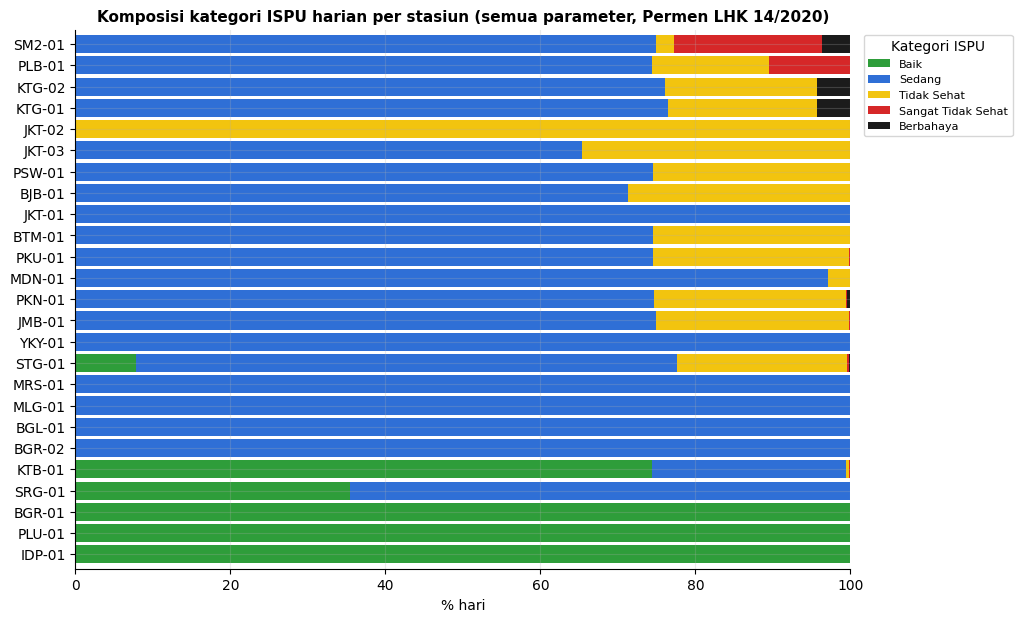

In [9]:
ISPU_BP = {"pm10": [0, 50, 150, 350, 420, 500], "pm25": [0, 15.5, 55.4, 150.4, 250.4, 500],
           "so2": [0, 52, 180, 400, 800, 1200], "co": [0, 4000, 8000, 15000, 30000, 45000],
           "o3": [0, 120, 235, 400, 800, 1000], "no2": [0, 80, 200, 1130, 2260, 3000]}
ISPU_IDX = [0, 50, 100, 200, 300, 500]
PNAME = {"pm25": "PM2.5", "pm10": "PM10", "so2": "SO₂", "co": "CO", "o3": "O₃", "no2": "NO₂"}
for p, bp in ISPU_BP.items():
    D[f"ispu_{p}"] = np.where(D[p].notna(), np.round(np.interp(D[p], bp, ISPU_IDX)), np.nan)
sub = D[[f"ispu_{p}" for p in ISPU_BP]]
D["ispu"] = sub.max(axis=1)
D["kategori"] = pd.cut(D["ispu"], [-1, 50, 100, 200, 300, np.inf], labels=ISPU_LAB)
has = sub.notna().any(axis=1)
D["polutan_kritis"] = sub[has].idxmax(axis=1).str.replace("ispu_", "").map(PNAME).reindex(D.index)
ok = D.dropna(subset=["ispu"])
print("Parameter pencemar kritis (share hari-stasiun):", ok.polutan_kritis.value_counts(normalize=True).mul(100).round(1).to_dict())
gas_kritis = ok[~ok.polutan_kritis.isin(["PM2.5", "PM10"])]
print(f"Hari ketika gas menjadi pencemar kritis: {len(gas_kritis)} dari {len(ok)} hari-stasiun",
      gas_kritis.groupby(["code", "polutan_kritis"]).size().sort_values(ascending=False).head(5).to_dict())
gas_max = {PNAME[p]: int(D[f"ispu_{p}"].max()) for p in ["so2", "co", "o3", "no2"]}
print("ISPU tertinggi yang pernah dicapai tiap gas:", gas_max, "→ tidak ada gas yang mencapai kategori Tidak Sehat" if max(gas_max.values()) <= 100 else "")
kat = pd.crosstab(D["code"], D["kategori"], normalize="index").mul(100).reindex(summ.index)
fig, ax = plt.subplots(figsize=(10, 7))
kat[::-1].plot(kind="barh", stacked=True, color=ISPU_COL, ax=ax, width=0.85)
ax.set_xlabel("% hari"); ax.set_ylabel("")
ax.legend(title="Kategori ISPU", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_title("Komposisi kategori ISPU harian per stasiun (semua parameter, Permen LHK 14/2020)")
savefig("04_ispu_komposisi")

### Indeks Kualitas Udara (IKU)
Rumus resmi **Permen LHK 27/2021 tentang Indeks Kualitas Lingkungan Hidup, Lampiran** (diverifikasi dari dokumen resmi; contoh perhitungan Kab. Bantul di Permen: NO₂ 14,81 & SO₂ 3,38 → IKU 90,57):

- Indeks NO₂ = rata-rata tahunan NO₂ / 40 µg/m³ · Indeks SO₂ = rata-rata tahunan SO₂ / 20 µg/m³ (baku mutu referensi EU)
- I_EU = (Indeks NO₂ + Indeks SO₂) / 2
- **IKU = 100 − (50 / 0,9) × (I_EU − 0,1)**
- Kategori: Sangat Baik 90–100 · Baik 70–<90 · Sedang 50–<70 · Kurang 25–<50 · Sangat Kurang 0–<25

Catatan: database peraturan BPK mencatat Permen 27/2021 berstatus tidak berlaku, tetapi booklet lomba menyebutnya sebagai acuan, sehingga tetap dipakai di sini. IKU dihitung per stasiun (≈ satu kabupaten/kota) dan per provinsi (rata-rata stasiun), untuk tahun penuh 2024 dan 2025 dengan syarat ≥ 75% hari valid.

,code,provinsi,kelompok,no2,so2,I_EU,IKU,kategori_IKU,pm25
13,JKT-02,DKI Jakarta,Industri,61.87,32.01,1.57,18.13,Sangat Kurang,60.03
15,JKT-03,DKI Jakarta,Roadside,59.93,21.98,1.30,33.41,Kurang,54.01
11,JKT-01,DKI Jakarta,Urban,56.00,20.01,1.20,38.87,Kurang,48.05
25,MDN-01,Sumatera Utara,Urban,37.73,9.18,0.70,66.61,Sedang,45.30
41,SM2-01,Kalimantan Timur,Industri,24.99,11.97,0.61,71.58,Baik,76.48
47,YKY-01,D.I. Yogyakarta,Urban,27.28,10.07,0.59,72.62,Baik,39.65
23,KTG-02,Kalimantan Tengah,Gambut,22.00,11.00,0.55,75.00,Baik,44.86
21,KTG-01,Kalimantan Tengah,Gambut,21.98,11.00,0.55,75.01,Baik,44.77
35,PLB-01,Sumatera Selatan,Gambut,22.44,8.52,0.49,78.14,Baik,67.01
39,PSW-01,Lampung,Urban,20.73,7.49,0.45,80.75,Baik,51.17


tahun,2024,2025
provinsi,,
DKI Jakarta,30.10,30.10
Sumatera Utara,66.80,66.60
Kalimantan Timur,71.40,71.60
D.I. Yogyakarta,72.60,72.60
Kalimantan Tengah,77.30,77.40
Sumatera Selatan,78.10,78.10
Lampung,80.70,80.80
Jawa Barat,81.20,81.20
Papua Barat Daya,82.10,82.00


Korelasi IKU vs rata-rata PM2.5 (2025): rho = -0.51 (p = 0.010)
Stasiun ber-IKU 'Baik/Sangat Baik' padahal PM2.5 tahunannya > 35 (gagal target WHO IT-1): ['SM2-01', 'YKY-01', 'KTG-02', 'KTG-01', 'PLB-01', 'PSW-01', 'MRS-01', 'STG-01', 'JMB-01', 'PKU-01', 'PKN-01', 'BTM-01']


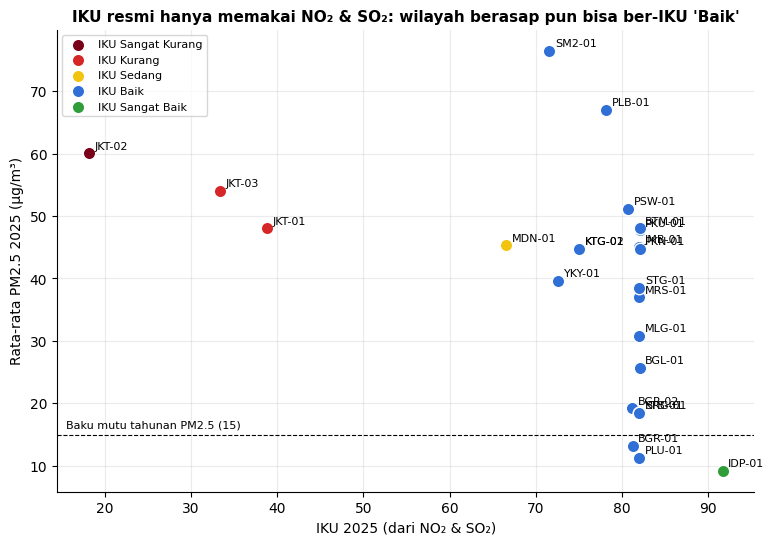

In [10]:
IKU_LAB = ["Sangat Kurang", "Kurang", "Sedang", "Baik", "Sangat Baik"]
IKU_COL = ["#7a0019", "#d62728", "#f2c40f", "#2f6fd6", "#2e9d3a"]
iku = (D[D.tahun.isin([2024, 2025])].groupby(["code", "tahun"])
       .agg(no2=("no2", "mean"), so2=("so2", "mean"), pm25=("pm25", "mean"), hari=("no2", "count")).reset_index())
iku = iku[iku.hari >= 0.75 * iku.tahun.map({2024: 366, 2025: 365})]
iku["I_EU"] = (iku.no2 / 40 + iku.so2 / 20) / 2
iku["IKU"] = (100 - (50 / 0.9) * (iku.I_EU - 0.1)).clip(0, 100)
iku["kategori_IKU"] = pd.cut(iku.IKU, [-0.1, 25, 50, 70, 90, 100.1], right=False, labels=IKU_LAB)
iku = iku.merge(st[["code", "provinsi", "kelompok"]], on="code")
iku25 = iku[iku.tahun == 2025].sort_values("IKU")
display(iku25[["code", "provinsi", "kelompok", "no2", "so2", "I_EU", "IKU", "kategori_IKU", "pm25"]].round(2))
prov = iku.groupby(["provinsi", "tahun"]).IKU.mean().unstack().round(1)
display(prov.sort_values(2025))
rho_iku, p_iku = stats.spearmanr(iku25.IKU, iku25.pm25)
print(f"Korelasi IKU vs rata-rata PM2.5 (2025): rho = {rho_iku:.2f} (p = {p_iku:.3f})")
blind = iku25[(iku25.kategori_IKU.isin(["Baik", "Sangat Baik"])) & (iku25.pm25 > 35)]
print("Stasiun ber-IKU 'Baik/Sangat Baik' padahal PM2.5 tahunannya > 35 (gagal target WHO IT-1):", blind.code.tolist())

fig, ax = plt.subplots(figsize=(9, 6))
for lab, c in zip(IKU_LAB, IKU_COL):
    g = iku25[iku25.kategori_IKU == lab]
    ax.scatter(g.IKU, g.pm25, s=80, color=c, label=f"IKU {lab}", edgecolor="white", zorder=3)
for _, r in iku25.iterrows():
    ax.annotate(r.code, (r.IKU, r.pm25), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.axhline(15, color="k", ls="--", lw=0.8); ax.text(ax.get_xlim()[0] + 1, 16, "Baku mutu tahunan PM2.5 (15)", fontsize=8)
ax.set_xlabel("IKU 2025 (dari NO₂ & SO₂)"); ax.set_ylabel("Rata-rata PM2.5 2025 (µg/m³)")
ax.set_title("IKU resmi hanya memakai NO₂ & SO₂: wilayah berasap pun bisa ber-IKU 'Baik'")
ax.legend(fontsize=8)
savefig("04b_iku_vs_pm25")

### Tren: periode yang sama tiap tahun (1 Jan – 14 Okt)
Tren dipisah per kelompok, karena separuh stasiun nyaris datar sehingga satu angka "nasional" atau median menyembunyikan tren di gambut. Tren juga dipisah antara **luar musim asap (Jan–Jun)** dan **musim asap (Jul–14 Okt)** untuk membedakan pemburukan kronis dan episodik.

,2024,2025,2026,ubah_%,ubah_Jan–Jun_%,ubah_Jul–14 Okt_%,kelompok,gambut
code,,,,,,,,
KTG-01,30.51,44.84,120.67,295.54,-0.51,541.61,Gambut,Gambut
KTG-02,30.54,45.00,120.74,295.38,-0.12,539.70,Gambut,Gambut
PKN-01,34.22,45.26,60.21,75.96,-0.03,121.56,Gambut,Gambut
STG-01,30.15,38.88,48.26,60.06,0.27,98.19,Gambut,Gambut
KTB-01,15.28,18.62,23.11,51.22,-0.63,89.11,Latar Bersih,Non-gambut
PLB-01,56.49,67.10,75.17,33.07,0.03,56.93,Gambut,Gambut
JMB-01,38.47,45.13,51.17,33.00,-0.10,59.60,Gambut,Gambut
PKU-01,41.25,47.75,53.50,29.68,0.36,54.02,Gambut,Gambut
BTM-01,43.00,47.91,52.52,22.13,-0.02,42.06,Industri,Non-gambut


,2024,2025,2026,ubah_%
gambut,,,,
Gambut,37.38,47.71,75.67,102.47
Non-gambut,35.51,35.84,36.67,3.25


Stasiun datar (|perubahan| ≤ 2%): 13 dari 24


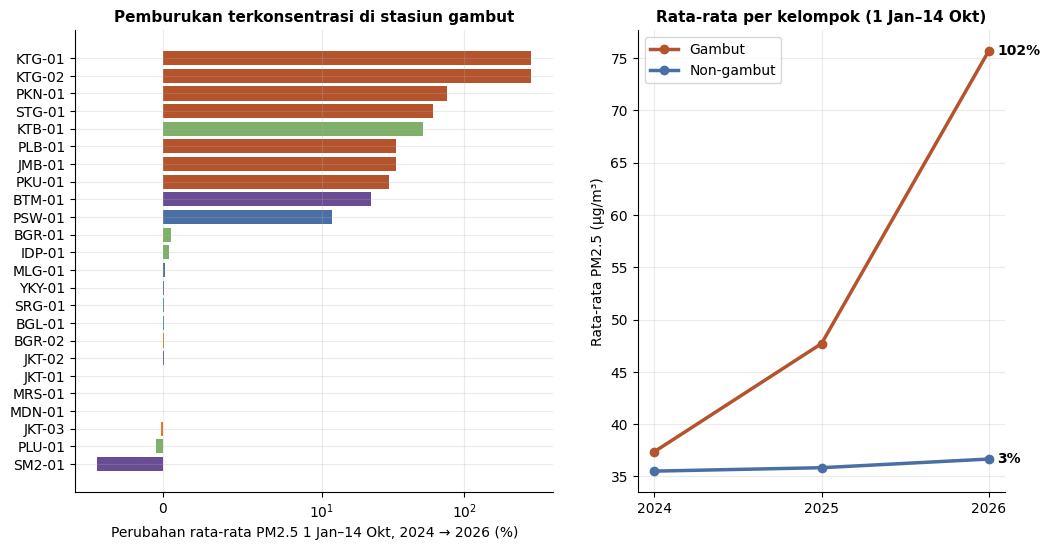

In [11]:
P = D[(D.md >= "01-01") & (D.md <= "10-14")].copy()
P["musim"] = np.where(P.bulan <= 6, "Jan–Jun", "Jul–14 Okt")
tr = P.groupby(["code", "tahun"]).pm25.mean().unstack()
tr["ubah_%"] = (tr[2026] / tr[2024] - 1) * 100
trs = P.groupby(["code", "musim", "tahun"]).pm25.mean().unstack()
trs["ubah_%"] = (trs[2026] / trs[2024] - 1) * 100
trs = trs["ubah_%"].unstack().rename(columns=lambda c: f"ubah_{c}_%")
tr = tr.join(trs).join(st.set_index("code")[["kelompok", "gambut"]])
TREND_EXCL = ["BJB-01", "MER-01"]   # cakupan < 75% sehingga rata-rata periode bias
trv = tr.drop(index=[c for c in TREND_EXCL if c in tr.index])
display(tr.sort_values("ubah_%", ascending=False))
grp = trv.groupby("gambut")[[2024, 2025, 2026]].mean()
grp["ubah_%"] = (grp[2026] / grp[2024] - 1) * 100
display(grp)
print("Stasiun datar (|perubahan| ≤ 2%):", int((trv["ubah_%"].abs() <= 2).sum()), "dari", len(trv))

fig, axes = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={"width_ratios": [1.3, 1]})
o = trv.sort_values("ubah_%")
axes[0].barh(o.index, o["ubah_%"], color=o["kelompok"].map(KELOMPOK_COL))
axes[0].set_xscale("symlog", linthresh=10)
axes[0].set_xlabel("Perubahan rata-rata PM2.5 1 Jan–14 Okt, 2024 → 2026 (%)")
axes[0].set_title("Pemburukan terkonsentrasi di stasiun gambut")
for k in ["Gambut", "Non-gambut"]:
    axes[1].plot([2024, 2025, 2026], grp.loc[k, [2024, 2025, 2026]], marker="o", lw=2.5,
                 color="#b5542c" if k == "Gambut" else "#4a6fa5", label=k)
    axes[1].text(2026.05, grp.loc[k, 2026], f"{fmt(grp.loc[k, 'ubah_%'], 0)}%", va="center", fontweight="bold")
axes[1].set_xticks([2024, 2025, 2026]); axes[1].set_ylabel("Rata-rata PM2.5 (µg/m³)")
axes[1].set_title("Rata-rata per kelompok (1 Jan–14 Okt)"); axes[1].legend()
savefig("05_tren")

### Tipologi stasiun (Model M1: clustering)
Apakah pembagian **kronis vs episodik** muncul dari data, bukan dipaksakan?

Clustering dilakukan pada **bentuk pola waktu** saja (tanpa level konsentrasi), supaya stasiun dikelompokkan berdasarkan *perilakunya*:
- `lonjakan` = log(persentil 95 / median): seberapa ekstrem hari terburuknya
- `musiman` = log(rata-rata Jul–Okt / rata-rata Jan–Jun): seberapa besar efek musim asap

Level konsentrasi lalu dipakai untuk memberi nama dengan acuan regulasi: **> 35 µg/m³** (belum capai target antara WHO paling longgar) = kronis, **≤ 15** (memenuhi baku mutu tahunan) = latar bersih.

In [12]:
hp = hourly[~hourly.code.isin(EXCL)].copy()
hp["jam_lokal"] = hp["ts_local"].dt.hour
diu = hp.groupby(["code", "jam_lokal"]).pm25.mean().unstack()
gq = D[~D.code.isin(LOWCOV)].groupby("code").pm25
feat = pd.DataFrame({
    "lonjakan": np.log(gq.quantile(0.95) / gq.median()),
    "musiman": np.log(D[D.bulan.between(7, 10)].groupby("code").pm25.mean() / D[D.bulan.between(1, 6)].groupby("code").pm25.mean()),
}).dropna()
Z = StandardScaler().fit_transform(feat)
sil = {k: silhouette_score(Z, KMeans(k, n_init=50, random_state=42).fit_predict(Z)) for k in range(2, 6)}
K = max(sil, key=sil.get)
km = KMeans(K, n_init=50, random_state=42).fit(Z)
hc = AgglomerativeClustering(K, linkage="ward").fit_predict(Z)
print("Silhouette per k:", {k: round(v, 3) for k, v in sil.items()}, f"→ k = {K}")
print(f"Kesepakatan KMeans vs hierarchical (ARI) = {adjusted_rand_score(km.labels_, hc):.2f}")
feat["cluster"] = km.labels_
cm = feat.groupby("cluster")[["lonjakan", "musiman"]].mean()
epi = cm["musiman"].idxmax()
feat["pola"] = np.where(feat.cluster == epi, "Episodik", "Stabil")
feat["rata2"] = summ["rata2_pm25"]
def tipe(r):
    if r.pola == "Episodik": return "Episodik (asap musiman)"
    if r.rata2 > 35: return "Kronis (tinggi & stabil)"
    if r.rata2 <= 15: return "Latar bersih"
    return "Sedang & stabil"
feat["tipe"] = feat.apply(tipe, axis=1)
display(feat.groupby("tipe").agg(n=("rata2", "size"), rata2=("rata2", "mean"),
                                 musiman_x=("musiman", lambda s: np.exp(s).mean()),
                                 lonjakan_x=("lonjakan", lambda s: np.exp(s).mean()),
                                 anggota=("rata2", lambda s: ", ".join(s.index))))
st = st.drop(columns=["tipe"], errors="ignore").merge(feat[["tipe"]], left_on="code", right_index=True, how="left")
print("Catatan: IDP-01 punya pola harian paling ekstrem (rasio jam max/min =", round(diu.loc["IDP-01"].max() / diu.loc["IDP-01"].min(), 1),
      ", puncak jam", int(diu.loc["IDP-01"].idxmax()), "lokal), anomali yang perlu dicek.")

Silhouette per k: {2: 0.686, 3: 0.656, 4: 0.634, 5: 0.684} → k = 2
Kesepakatan KMeans vs hierarchical (ARI) = 0.69


,n,rata2,musiman_x,lonjakan_x,anggota
tipe,,,,,
Episodik (asap musiman),10,50.93,3.93,4.67,"BTM-01, JMB-01, KTB-01, KTG-01, KTG-02, PKN-01, PKU-01, PLB-01, SM2-01, STG-01"
Kronis (tinggi & stabil),8,48.03,1.44,1.50,"BJB-01, JKT-01, JKT-02, JKT-03, MDN-01, MRS-01, PSW-01, YKY-01"
Latar bersih,3,11.28,1.17,1.19,"BGR-01, IDP-01, PLU-01"
Sedang & stabil,4,23.47,1.38,1.28,"BGL-01, BGR-02, MLG-01, SRG-01"


Catatan: IDP-01 punya pola harian paling ekstrem (rasio jam max/min = 4.6 , puncak jam 5 lokal), anomali yang perlu dicek.


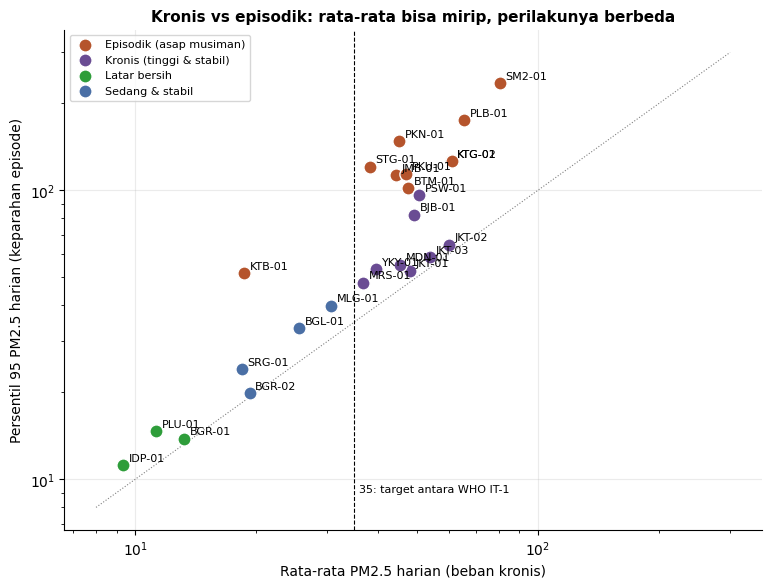

In [13]:
TIPE_COL = {"Episodik (asap musiman)": "#b5542c", "Kronis (tinggi & stabil)": "#6a4c93",
            "Latar bersih": "#2e9d3a", "Sedang & stabil": "#4a6fa5"}
fig, ax = plt.subplots(figsize=(9, 6.5))
for t, gdf in feat.join(summ[["rata2_pm25", "p95_pm25"]]).groupby("tipe"):
    ax.scatter(gdf.rata2_pm25, gdf.p95_pm25, s=90, color=TIPE_COL[t], label=t, edgecolor="white", zorder=3)
    for c, r in gdf.iterrows():
        ax.annotate(c, (r.rata2_pm25, r.p95_pm25), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.plot([8, 300], [8, 300], color="grey", lw=0.8, ls=":")
ax.axvline(35, color="k", ls="--", lw=0.8); ax.text(36, 9, "35: target antara WHO IT-1", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Rata-rata PM2.5 harian (beban kronis)"); ax.set_ylabel("Persentil 95 PM2.5 harian (keparahan episode)")
ax.set_title("Kronis vs episodik: rata-rata bisa mirip, perilakunya berbeda")
ax.legend(fontsize=8)
savefig("06_kuadran_kronis_episodik")

---
## 3. Q2 · Waktu & Wilayah Paling Kritis
**Pertanyaan:** Kapan dan di mana pencemaran paling kritis (jam, hari kerja vs akhir pekan, musim, episode kabut asap), dan bagaimana bedanya antar tipe kawasan?

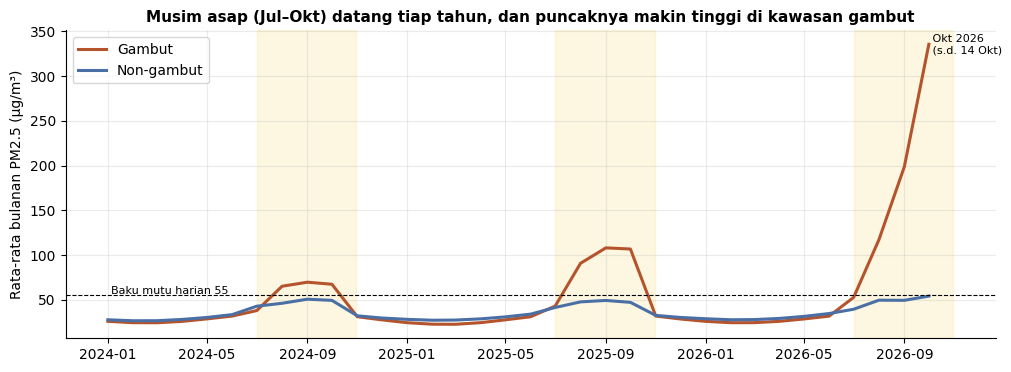

,max,idxmax
date,,
2024,69.59,2024-09
2025,107.98,2025-09
2026,335.59,2026-10


In [14]:
mon = D.groupby([D.date.dt.to_period("M"), "gambut"]).pm25.mean().unstack()
fig, ax = plt.subplots(figsize=(12, 4))
for k, c in [("Gambut", "#b5542c"), ("Non-gambut", "#4a6fa5")]:
    ax.plot(mon.index.to_timestamp(), mon[k], color=c, lw=2.2, label=k)
for y in [2024, 2025, 2026]:
    ax.axvspan(pd.Timestamp(f"{y}-07-01"), pd.Timestamp(f"{y}-10-31"), color="#f2c40f", alpha=0.12)
ax.axhline(55, color="k", ls="--", lw=0.8); ax.text(pd.Timestamp("2024-01-05"), 57, "Baku mutu harian 55", fontsize=8)
ax.text(pd.Timestamp("2026-10-01"), mon["Gambut"].iloc[-1], " Okt 2026\n (s.d. 14 Okt)", fontsize=8, va="center")
ax.set_ylabel("Rata-rata bulanan PM2.5 (µg/m³)"); ax.legend()
ax.set_title("Musim asap (Jul–Okt) datang tiap tahun, dan puncaknya makin tinggi di kawasan gambut")
savefig("07_musiman")
peak = mon["Gambut"].groupby(mon.index.year).agg(["max", "idxmax"])
display(peak)

### "Barcode polusi": setiap stasiun × setiap hari
Satu gambar untuk ±26 ribu hari-stasiun. Warna = kategori ISPU harian dari PM2.5.

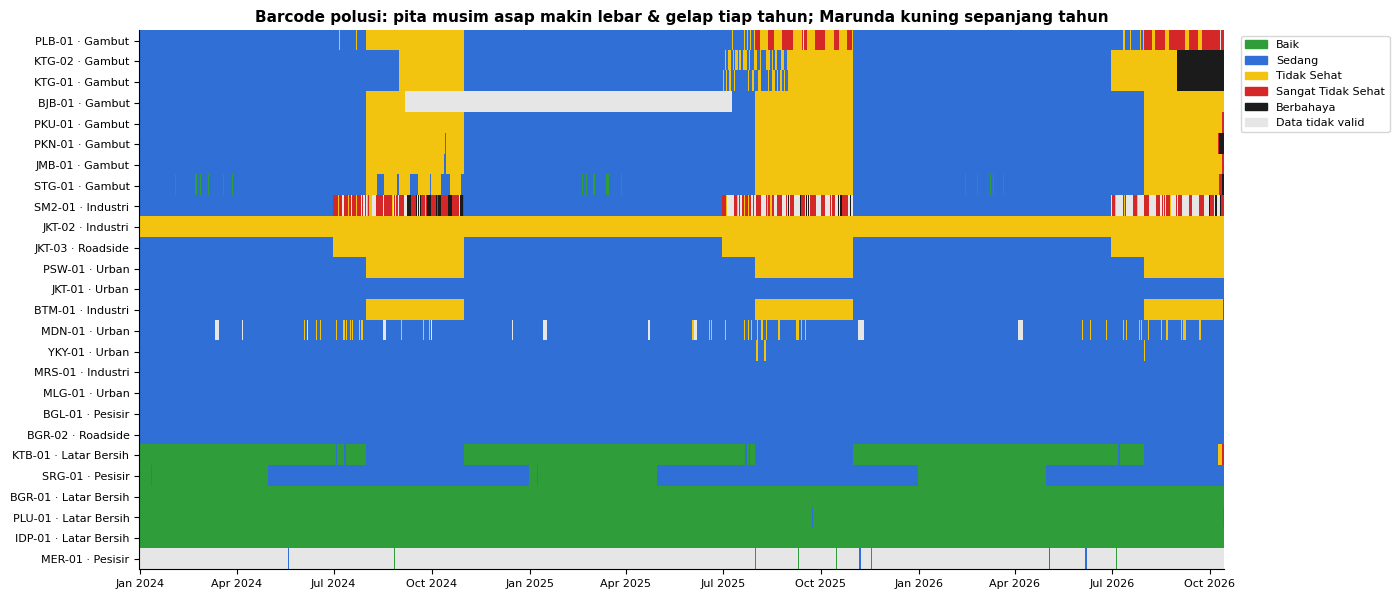

In [15]:
order = (st[~st.code.isin(EXCL)].assign(r=lambda x: x.code.map(summ.rata2_pm25))
         .sort_values(["gambut", "r"], ascending=[True, False]).code.tolist())
bar = D.pivot(index="code", columns="date", values="pm25").reindex(order)
cat = np.digitize(bar.values, [15.5, 55.4, 150.4, 250.4]).astype(float)
cat[np.isnan(bar.values)] = np.nan
cmap = mpl.colors.ListedColormap(ISPU_COL); cmap.set_bad("#e6e6e6")
fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(np.ma.masked_invalid(cat), aspect="auto", cmap=cmap, vmin=-0.5, vmax=4.5, interpolation="nearest")
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{c} · {st.set_index('code').loc[c, 'kelompok']}" for c in order], fontsize=8)
months = pd.date_range(bar.columns.min(), bar.columns.max(), freq="QS")
ax.set_xticks([bar.columns.get_loc(m) for m in months if m in bar.columns])
ax.set_xticklabels([m.strftime("%b %Y") for m in months if m in bar.columns], fontsize=8)
ax.grid(False)
handles = [mpl.patches.Patch(color=c, label=l) for c, l in zip(ISPU_COL, ISPU_LAB)] + [mpl.patches.Patch(color="#e6e6e6", label="Data tidak valid")]
ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_title("Barcode polusi: pita musim asap makin lebar & gelap tiap tahun; Marunda kuning sepanjang tahun")
savefig("08_barcode_polusi")

### Pola jam (waktu lokal) dan hari dalam seminggu

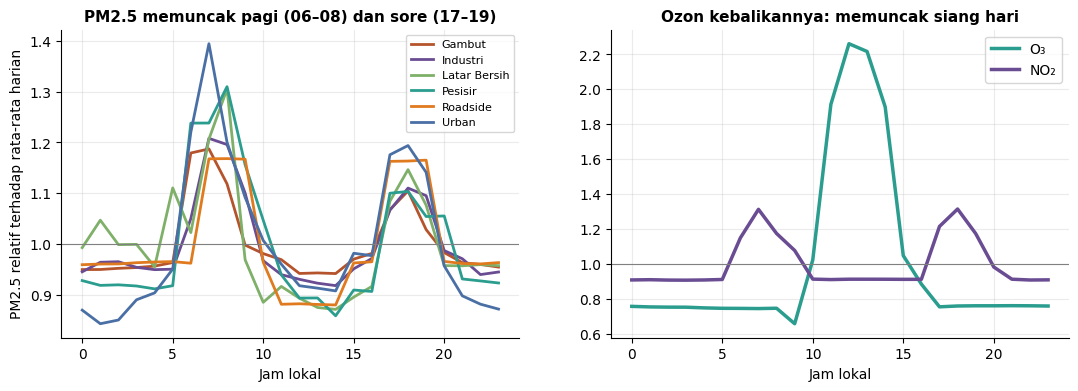

Jam puncak PM2.5 per kelompok: {'Gambut': 7, 'Industri': 7, 'Latar Bersih': 8, 'Pesisir': 8, 'Roadside': 8, 'Urban': 7}
O3: puncak jam 12, terendah jam 9, rasio 3.4x
Selisih akhir pekan vs hari kerja (%): median 0.03 | maks YKY-01 4.0 | min KTG-01 -3.2


In [16]:
hp["dow"] = hp["ts_local"].dt.dayofweek
hp = hp.merge(st[["code", "kelompok"]], on="code")
dprof = hp.groupby(["kelompok", "jam_lokal"]).pm25.mean().unstack()
dprof = dprof.div(dprof.mean(axis=1), axis=0)
o3 = hp.groupby("jam_lokal").o3.mean(); no2 = hp.groupby("jam_lokal").no2.mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, r in dprof.iterrows():
    axes[0].plot(r.index, r.values, label=k, color=KELOMPOK_COL[k], lw=2)
axes[0].axhline(1, color="grey", lw=0.8)
axes[0].set_xlabel("Jam lokal"); axes[0].set_ylabel("PM2.5 relatif terhadap rata-rata harian")
axes[0].set_title("PM2.5 memuncak pagi (06–08) dan sore (17–19)"); axes[0].legend(fontsize=8)
axes[1].plot(o3.index, o3 / o3.mean(), color="#2a9d8f", lw=2.5, label="O₃")
axes[1].plot(no2.index, no2 / no2.mean(), color="#6a4c93", lw=2.5, label="NO₂")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Jam lokal"); axes[1].set_title("Ozon kebalikannya: memuncak siang hari"); axes[1].legend()
savefig("09_pola_jam")
print("Jam puncak PM2.5 per kelompok:", dprof.idxmax(axis=1).to_dict())
print(f"O3: puncak jam {o3.idxmax()}, terendah jam {o3.idxmin()}, rasio {o3.max()/o3.min():.1f}x")

wk = hp.assign(akhir_pekan=hp.dow >= 5).groupby(["code", "akhir_pekan"]).pm25.mean().unstack()
wk["beda_%"] = (wk[True] / wk[False] - 1) * 100
print("Selisih akhir pekan vs hari kerja (%): median", round(wk["beda_%"].median(), 2),
      "| maks", wk["beda_%"].idxmax(), round(wk["beda_%"].max(), 1), "| min", wk["beda_%"].idxmin(), round(wk["beda_%"].min(), 1))

### Cek anomali pola harian IDP-01 (Indrapuri, Aceh)
IDP-01 punya rasio jam tertinggi/terendah PM2.5 paling ekstrem dan puncaknya dini hari. Apakah ini pola nyata, atau tanda jam pencatatan yang bergeser? Profil harian IDP-01 dibandingkan dengan profil "khas" stasiun lain (median profil ternormalisasi), digeser 0–23 jam.

Korelasi profil IDP-01 vs profil khas tanpa geser: -0.00 | terbaik bila digeser 10 jam: 0.22


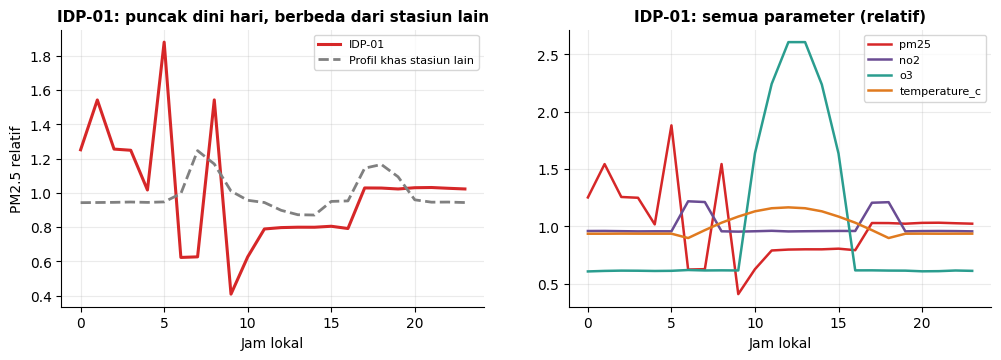

In [17]:
prof_n = diu.div(diu.mean(axis=1), axis=0)
khas = prof_n.drop(index=["IDP-01"]).median()
shift_r = {k: np.corrcoef(np.roll(prof_n.loc["IDP-01"].values, -k), khas.values)[0, 1] for k in range(24)}
best = max(shift_r, key=shift_r.get)
print(f"Korelasi profil IDP-01 vs profil khas tanpa geser: {shift_r[0]:.2f} | terbaik bila digeser {best} jam: {shift_r[best]:.2f}")
idp_g = hp[hp.code == "IDP-01"].groupby("jam_lokal")[["pm25", "no2", "co", "o3", "temperature_c"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(prof_n.columns, prof_n.loc["IDP-01"], color="#d62728", lw=2.2, label="IDP-01")
axes[0].plot(khas.index, khas.values, color="grey", lw=2, ls="--", label="Profil khas stasiun lain")
axes[0].set_xlabel("Jam lokal"); axes[0].set_ylabel("PM2.5 relatif"); axes[0].legend(fontsize=8)
axes[0].set_title("IDP-01: puncak dini hari, berbeda dari stasiun lain")
for c, col in [("pm25", "#d62728"), ("no2", "#6a4c93"), ("o3", "#2a9d8f"), ("temperature_c", "#e07a1f")]:
    axes[1].plot(idp_g.index, idp_g[c] / idp_g[c].mean(), label=c, color=col, lw=1.8)
axes[1].set_xlabel("Jam lokal"); axes[1].set_title("IDP-01: semua parameter (relatif)"); axes[1].legend(fontsize=8)
savefig("09b_cek_idp")

### Episode kabut asap & kalender risiko
**Episode berat** = minimal 3 hari berturut-turut dengan PM2.5 harian > 150,4 µg/m³ (kategori Sangat Tidak Sehat atau lebih buruk).
**Kalender risiko** = peluang sebuah hari-stasiun gambut berkategori *Tidak Sehat* atau lebih buruk (> 55,4), per minggu dalam setahun.

,jumlah_episode,total_hari,terpanjang,puncak
tahun,,,,
2024,11,84,31,340.94
2025,17,89,11,299.43
2026,20,198,44,"1,127.57"


,code,mulai,selesai,hari,puncak,tahun
0,KTG-01,2026-09-01,2026-10-14,44,"1,127.57",2026
1,KTG-02,2026-09-01,2026-10-14,44,"1,124.49",2026
25,SM2-01,2024-09-26,2024-10-26,31,317.60,2024
14,PLB-01,2026-09-24,2026-10-10,17,237.77,2026
12,PLB-01,2026-08-24,2026-09-07,15,193.05,2026
5,PLB-01,2025-08-26,2025-09-05,11,177.63,2025
7,PLB-01,2025-09-26,2025-10-05,10,177.27,2025
11,PLB-01,2026-08-11,2026-08-20,10,191.79,2026
23,SM2-01,2024-09-08,2024-09-17,10,340.94,2024
13,PLB-01,2026-09-12,2026-09-20,9,192.85,2026


Minggu pertama ≥50% hari-stasiun gambut 'Tidak Sehat': {2024: 32, 2025: 32, 2026: 31}


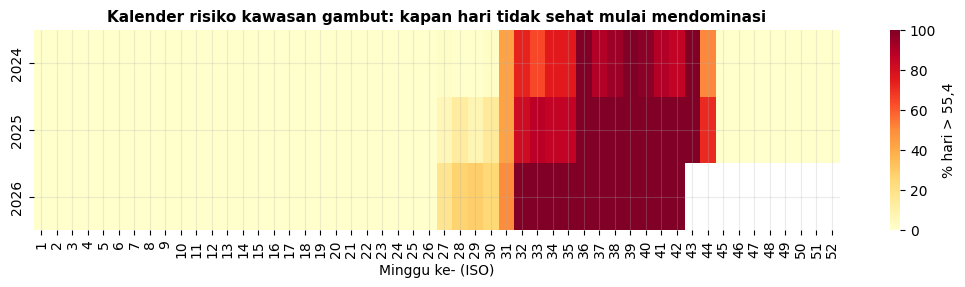

In [18]:
eps = []
for c, gdf in D.sort_values("date").groupby("code"):
    s = gdf.set_index("date")["pm25"].asfreq("D") > 150.4
    run = (s != s.shift()).cumsum()
    for _, r in s[s].groupby(run[s]):
        if len(r) >= 3:
            eps.append({"code": c, "mulai": r.index.min(), "selesai": r.index.max(), "hari": len(r),
                        "puncak": gdf.set_index("date").loc[r.index, "pm25"].max()})
eps = pd.DataFrame(eps)
eps["tahun"] = eps["mulai"].dt.year
eps_y = eps.groupby(["tahun"]).agg(jumlah_episode=("hari", "size"), total_hari=("hari", "sum"),
                                     terpanjang=("hari", "max"), puncak=("puncak", "max"))
display(eps_y)
display(eps.sort_values("hari", ascending=False).head(10))

G = D[D.gambut == "Gambut"].copy()
G["minggu"] = G.date.dt.isocalendar().week.astype(int).clip(upper=52)
cal = G.groupby(["tahun", "minggu"]).pm25.apply(lambda s: 100 * (s.dropna() > 55.4).mean()).unstack()
mulai = {y: int(r[r >= 50].index.min()) if (r >= 50).any() else None for y, r in cal.iterrows()}
print("Minggu pertama ≥50% hari-stasiun gambut 'Tidak Sehat':", mulai)
fig, ax = plt.subplots(figsize=(13, 2.6))
sns.heatmap(cal, cmap="YlOrRd", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% hari > 55,4"})
ax.set_xlabel("Minggu ke- (ISO)"); ax.set_ylabel("")
ax.set_title("Kalender risiko kawasan gambut: kapan hari tidak sehat mulai mendominasi")
savefig("10_kalender_risiko")

---
## 4. Q3 · Faktor yang Memengaruhi PM2.5
**Pertanyaan:** Faktor apa yang paling menentukan variasi PM2.5: suhu, kelembapan, angin, lalu lintas, jarak ke jalan, tipe lokasi, atau musim?

Pertanyaan ini dijawab dari tiga sisi:
1. **Dekomposisi variasi:** seberapa besar variasi PM2.5 berasal dari *lokasi*, *musim/episode*, *hari*, dan *jam*.
2. **Antar stasiun (n = 26):** kenapa ada stasiun yang selalu lebih kotor? (korelasi dengan atribut lokasi, di luar musim asap)
3. **Dalam stasiun (Model M2: LightGBM + SHAP):** kenapa PM2.5 naik-turun dari waktu ke waktu?

,Lokasi (antar stasiun),Musim/episode (stasiun-bulan),Hari ke hari
Skala asli (µg/m³),16.10,81.60,2.20
Skala log,59.30,40.20,0.50


Variasi jam-dalam-sehari = 8.6% dari variasi data per jam


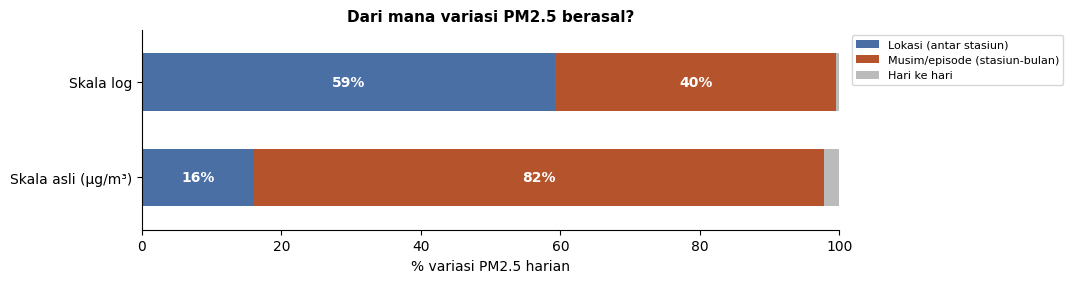

In [19]:
dd = D.dropna(subset=["pm25"]).copy()
dd["ym"] = dd.date.dt.to_period("M")
def decomp(y, frame):
    tot = y.var()
    r1 = y - y.groupby(frame.code).transform("mean")
    r2 = r1 - r1.groupby([frame.code, frame.ym]).transform("mean")
    return {"Lokasi (antar stasiun)": 1 - r1.var() / tot, "Musim/episode (stasiun-bulan)": (r1.var() - r2.var()) / tot,
            "Hari ke hari": r2.var() / tot}
dec = pd.DataFrame({"Skala asli (µg/m³)": decomp(dd.pm25, dd), "Skala log": decomp(np.log(dd.pm25.clip(lower=1)), dd)}).T * 100
hh = hp.dropna(subset=["pm25"])
within_day = (hh.pm25 - hh.groupby(["code", hh.ts.dt.normalize()]).pm25.transform("mean")).var() / hh.pm25.var() * 100
display(dec.round(1))
print(f"Variasi jam-dalam-sehari = {within_day:.1f}% dari variasi data per jam")
fig, ax = plt.subplots(figsize=(9, 2.6))
dec.plot(kind="barh", stacked=True, ax=ax, color=["#4a6fa5", "#b5542c", "#bbbbbb"], width=0.6)
for i, (idx, r) in enumerate(dec.iterrows()):
    left = 0
    for v in r.values:
        if v > 4: ax.text(left + v / 2, i, f"{fmt(v, 0)}%", ha="center", va="center", color="white", fontweight="bold")
        left += v
ax.set_xlim(0, 100); ax.set_xlabel("% variasi PM2.5 harian"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); ax.grid(False)
ax.set_title("Dari mana variasi PM2.5 berasal?")
savefig("11_dekomposisi_variasi")

,atribut,polutan (Jan–Jun),rho_spearman,p_value
0,traffic_intensity_per_h,pm25,0.78,0.00
1,traffic_intensity_per_h,no2,0.44,0.02
2,traffic_intensity_per_h,co,0.36,0.07
3,distance_to_road_m,pm25,-0.68,0.00
4,distance_to_road_m,no2,-0.40,0.04
5,distance_to_road_m,co,-0.36,0.07


Korelasi lalu lintas vs jarak ke jalan: -0.83


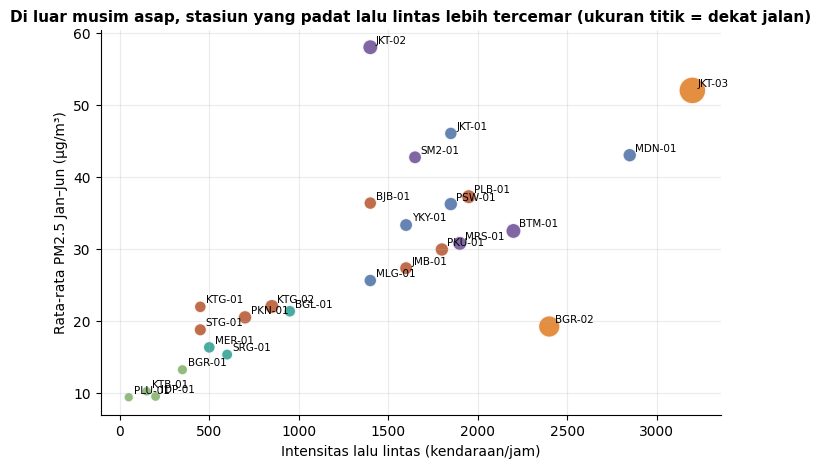

In [20]:
nonhaze = D[D.bulan.between(1, 6)].groupby("code")[["pm25", "no2", "co"]].mean()
attr = nonhaze.join(st.set_index("code")[["traffic_intensity_per_h", "distance_to_road_m", "kelompok"]])
rows = []
for x in ["traffic_intensity_per_h", "distance_to_road_m"]:
    for y in ["pm25", "no2", "co"]:
        rho, p = stats.spearmanr(attr[x], attr[y])
        rows.append({"atribut": x, "polutan (Jan–Jun)": y, "rho_spearman": rho, "p_value": p})
display(pd.DataFrame(rows))
print("Korelasi lalu lintas vs jarak ke jalan:", round(stats.spearmanr(attr.traffic_intensity_per_h, attr.distance_to_road_m)[0], 2))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(attr.traffic_intensity_per_h, attr.pm25, s=40 + 2000 / attr.distance_to_road_m.clip(lower=5),
           c=attr.kelompok.map(KELOMPOK_COL), alpha=0.85, edgecolor="white")
for c, r in attr.iterrows():
    ax.annotate(c, (r.traffic_intensity_per_h, r.pm25), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.set_xlabel("Intensitas lalu lintas (kendaraan/jam)"); ax.set_ylabel("Rata-rata PM2.5 Jan–Jun (µg/m³)")
ax.set_title("Di luar musim asap, stasiun yang padat lalu lintas lebih tercemar (ukuran titik = dekat jalan)")
savefig("12_lalu_lintas")

**Model M2 (dalam stasiun).** Target: simpangan log PM2.5 harian dari rata-rata stasiunnya sendiri. Fitur: musim (bulan, hari-dalam-tahun), hari dalam seminggu, cuaca (suhu, kelembapan, kecepatan & arah angin), dan kelompok kawasan. **Tanpa ID stasiun dan tanpa `baseline_pm25`** (bocor target). Validasi: latih 2024–2025, uji 2026. Kontribusi tiap faktor dihitung dengan SHAP bawaan LightGBM (`pred_contrib`).

M2 · R² uji 2026 = 0.717 | R² latih = 0.941


Musim (bulan & hari-dalam-tahun)   71.40
Kelompok kawasan × musim           13.90
Angin (kecepatan & arah)            5.30
Kelembapan                          5.20
Suhu                                3.70
Hari dalam seminggu                 0.50
dtype: float64

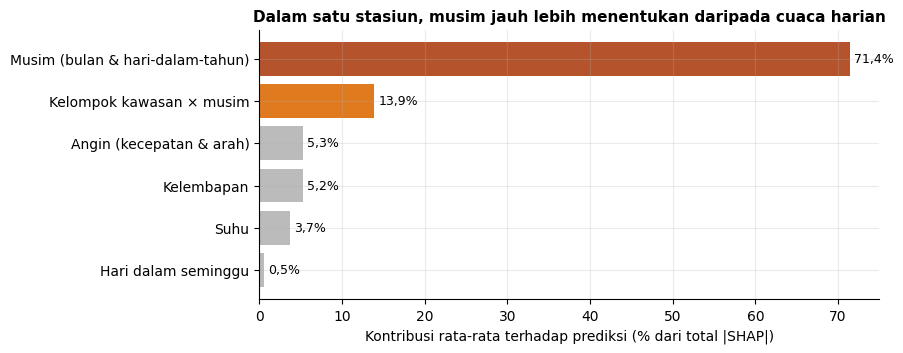

In [21]:
wind = hourly.groupby(["code", "date"])[["wind_direction_deg"]].agg(lambda s: np.degrees(np.arctan2(np.sin(np.radians(s)).mean(), np.cos(np.radians(s)).mean())) % 360)
M2 = D.merge(wind.reset_index(), on=["code", "date"], how="left").dropna(subset=["pm25", "temperature_c", "humidity_pct", "wind_speed_ms"]).copy()
M2["y"] = np.log(M2.pm25.clip(lower=1))
M2["y"] = M2["y"] - M2.groupby("code")["y"].transform("mean")
M2["doy"] = M2.date.dt.dayofyear
M2["doy_sin"], M2["doy_cos"] = np.sin(2 * np.pi * M2.doy / 365.25), np.cos(2 * np.pi * M2.doy / 365.25)
M2["dow"] = M2.date.dt.dayofweek
M2["wd_sin"], M2["wd_cos"] = np.sin(np.radians(M2.wind_direction_deg)), np.cos(np.radians(M2.wind_direction_deg))
M2["kelompok_c"] = M2["kelompok"].astype("category")
F2 = ["bulan", "doy_sin", "doy_cos", "dow", "temperature_c", "humidity_pct", "wind_speed_ms", "wd_sin", "wd_cos", "kelompok_c"]
tr2, te2 = M2[M2.tahun <= 2025], M2[M2.tahun == 2026]
m2 = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.9, random_state=42, verbose=-1)
m2.fit(tr2[F2], tr2["y"])
pred2 = m2.predict(te2[F2])
print(f"M2 · R² uji 2026 = {r2_score(te2.y, pred2):.3f} | R² latih = {r2_score(tr2.y, m2.predict(tr2[F2])):.3f}")
contrib = m2.predict(te2[F2], pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(contrib).mean(axis=0), index=F2)
grup = {"Musim (bulan & hari-dalam-tahun)": ["bulan", "doy_sin", "doy_cos"], "Kelompok kawasan × musim": ["kelompok_c"],
        "Hari dalam seminggu": ["dow"], "Suhu": ["temperature_c"], "Kelembapan": ["humidity_pct"],
        "Angin (kecepatan & arah)": ["wind_speed_ms", "wd_sin", "wd_cos"]}
shap_g = pd.Series({k: shap_imp[v].sum() for k, v in grup.items()}).sort_values()
shap_g_pct = 100 * shap_g / shap_g.sum()
display(shap_g_pct.round(1).sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(shap_g_pct.index, shap_g_pct.values, color=["#bbbbbb"] * (len(shap_g_pct) - 2) + ["#e07a1f", "#b5542c"])
for i, v in enumerate(shap_g_pct.values):
    ax.text(v + 0.5, i, f"{fmt(v, 1)}%", va="center", fontsize=9)
ax.set_xlabel("Kontribusi rata-rata terhadap prediksi (% dari total |SHAP|)")
ax.set_title("Dalam satu stasiun, musim jauh lebih menentukan daripada cuaca harian")
savefig("13_shap_pemicu")

In [22]:
met_rows = []
for c, gdf in hourly[~hourly.code.isin(EXCL)].groupby("code"):
    gdf = gdf.dropna(subset=["pm25"])
    r = {"code": c}
    for m in ["temperature_c", "humidity_pct", "wind_speed_ms"]:
        r[m] = stats.spearmanr(gdf.pm25, gdf[m], nan_policy="omit")[0]
    met_rows.append(r)
met = pd.DataFrame(met_rows).set_index("code")
print("Korelasi Spearman per jam (median antar stasiun):", met.median().round(2).to_dict())
jk = hourly[hourly.code.isin(["JKT-01", "JKT-02", "JKT-03"])].pivot(index="ts", columns="code", values="temperature_c")
print("Suhu JKT-01 = JKT-02 = JKT-03 persis:", f"{100 * ((jk['JKT-01'] == jk['JKT-02']) & (jk['JKT-02'] == jk['JKT-03'])).mean():.1f}% jam",
      "| korelasi suhu JKT-01 vs JKT-02:", round(jk['JKT-01'].corr(jk['JKT-02']), 3))

Korelasi Spearman per jam (median antar stasiun): {'temperature_c': -0.12, 'humidity_pct': 0.01, 'wind_speed_ms': 0.08}
Suhu JKT-01 = JKT-02 = JKT-03 persis: 0.1% jam | korelasi suhu JKT-01 vs JKT-02: 0.857


### Arah angin (*pollution rose*) di stasiun industri & tepi jalan
Rata-rata PM2.5 dan SO₂ per arah asal angin (8 sektor), relatif terhadap rata-rata stasiun. Kalau ada sumber emisi di satu arah, sektor itu akan menonjol.

,pm25_min,pm25_max,so2_min,so2_max,rentang_pm25_%
code,,,,,
BGR-02,1.00,1.00,1.00,1.00,0.01
BTM-01,0.99,1.00,0.98,1.00,1.14
JKT-02,1.00,1.00,1.00,1.00,0.58
JKT-03,1.00,1.00,1.00,1.00,0.34
MRS-01,0.99,1.01,1.00,1.00,1.23
SM2-01,0.97,1.03,0.99,1.01,6.11


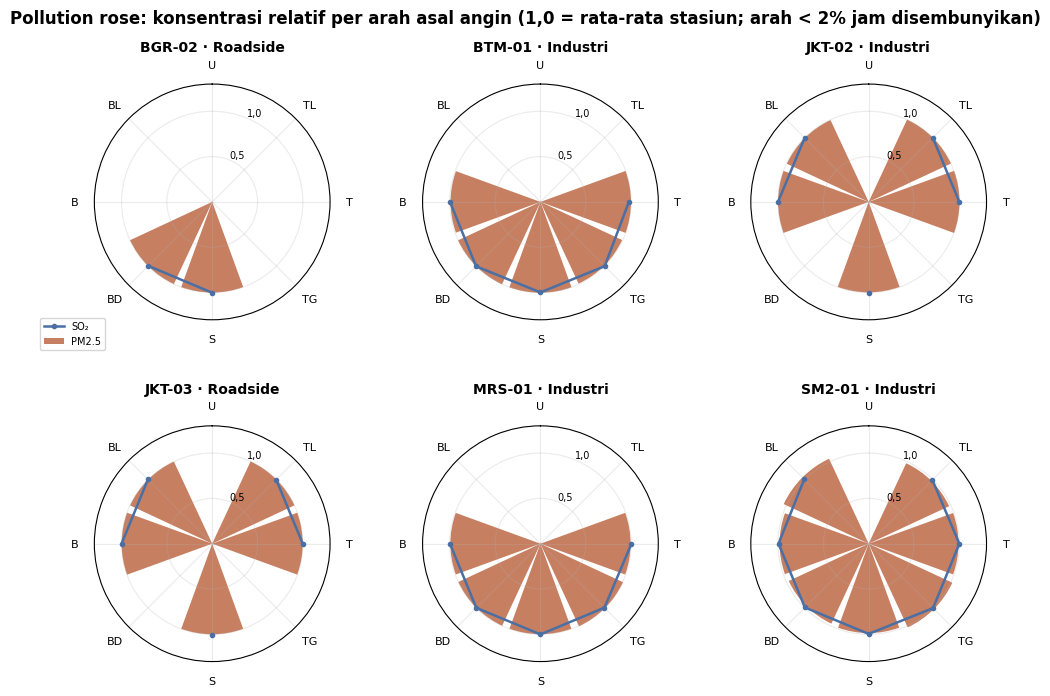

In [23]:
SECT = ["U", "TL", "T", "TG", "S", "BD", "B", "BL"]
W = hourly[hourly.code.isin(["JKT-02", "BTM-01", "MRS-01", "SM2-01", "JKT-03", "BGR-02"])].dropna(subset=["wind_direction_deg", "pm25"]).copy()
W["sektor"] = pd.Categorical(np.array(SECT)[(((W.wind_direction_deg + 22.5) % 360) // 45).astype(int)], SECT)
rose = W.groupby(["code", "sektor"], observed=False).agg(pm25=("pm25", "mean"), so2=("so2", "mean"), jam=("pm25", "size"))
rose["pm25_rel"] = rose.pm25 / W.groupby("code").pm25.mean().reindex(rose.index.get_level_values(0)).values
rose["so2_rel"] = rose.so2 / W.groupby("code").so2.mean().reindex(rose.index.get_level_values(0)).values
rose["jam_%"] = 100 * rose.jam / rose.groupby(level=0).jam.transform("sum")
rr = rose[rose["jam_%"] >= 2]
spread = rr.groupby(level=0).agg(pm25_min=("pm25_rel", "min"), pm25_max=("pm25_rel", "max"), so2_min=("so2_rel", "min"), so2_max=("so2_rel", "max"))
spread["rentang_pm25_%"] = 100 * (spread.pm25_max - spread.pm25_min)
display(spread.round(2))
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), subplot_kw={"projection": "polar"})
ang = np.radians(np.arange(0, 360, 45))
for ax, (c, g) in zip(axes.flat, rose.groupby(level=0)):
    g = g.droplevel(0).reindex(SECT)
    g.loc[g["jam_%"] < 2, ["pm25_rel", "so2_rel"]] = np.nan   # arah angin yang terlalu jarang tidak ditampilkan
    ax.bar(ang, g["pm25_rel"].fillna(0), width=np.radians(40), color="#b5542c", alpha=0.75, label="PM2.5")
    ax.plot(np.append(ang, ang[0]), np.append(g["so2_rel"].values, g["so2_rel"].values[0]), color="#4a6fa5", lw=1.8, marker="o", ms=3, label="SO₂")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_xticks(ang); ax.set_xticklabels(SECT, fontsize=8); ax.set_ylim(0, 1.3)
    ax.set_yticks([0.5, 1.0]); ax.set_yticklabels(["0,5", "1,0"], fontsize=7)
    ax.set_title(f"{c} · {st.set_index('code').loc[c, 'kelompok']}", fontsize=10)
axes.flat[0].legend(loc="lower left", fontsize=7, bbox_to_anchor=(-0.25, -0.15))
plt.suptitle("Pollution rose: konsentrasi relatif per arah asal angin (1,0 = rata-rata stasiun; arah < 2% jam disembunyikan)", fontweight="bold")
plt.subplots_adjust(hspace=0.45)
savefig("13b_pollution_rose")

---
## 5. Q4 · Dampak Kesehatan
**Pertanyaan:** Seberapa besar dan seberapa cepat kenaikan PM2.5 berdampak pada ISPA, asma, PPOK, kardiovaskular, dan kematian, dan kelompok mana (balita vs lansia) yang paling rentan?

Data: 27 RS × ±1.018 hari, digabung dengan PM2.5 harian stasiun pasangannya. **RS-23 (MER-01) dan RS-27 (JMB-02) dikeluarkan dari model** karena tidak punya pasangan PM harian yang layak.

Strategi analisis (dari yang paling sederhana ke paling ketat):
1. **Deskriptif:** kasus relatif terhadap rata-rata RS sendiri, per kategori ISPU.
2. **Bentuk hubungan:** apakah efeknya linear terhadap PM2.5 atau terhadap log PM2.5?
3. **Model dua tahap (gaya NMMAPS):** Poisson per RS (kontrol tren-musim dengan spline waktu, suhu, hari) → digabung dengan meta-analisis *random effects*.
4. **Efek jeda + uji plasebo:** apakah efek bertahan beberapa hari, atau hanya karena asap bertahan berhari-hari?
5. **Model ML (LightGBM Poisson)** sebagai pembanding prediktif.
6. **Simulasi dampak** dari skenario PM2.5.

In [24]:
H = hl.merge(daily[["code", "date", "pm25"]], on=["code", "date"], how="left").sort_values(["hospital_id", "date"]).reset_index(drop=True)
H["t"] = (H["date"] - H["date"].min()).dt.days
H["pm"] = H["pm25"].clip(lower=1)
H["lpm_l0"] = np.log2(H["pm"])
gH = H.groupby("hospital_id")
for k in range(1, 8):
    H[f"lpm_l{k}"] = gH["lpm_l0"].shift(k)
    H[f"pm_l{k}"] = gH["pm"].shift(k)
for k in range(1, 4):
    H[f"lpm_f{k}"] = gH["lpm_l0"].shift(-k)
H["pm_l0"] = H["pm"]
H["pm_ma7"] = gH["pm"].transform(lambda s: s.rolling(7, min_periods=4).mean())
H["bulan"] = H["date"].dt.month
H["tahun"] = H["date"].dt.year
EXCL_H = ["RS-XXX-23", "RS-XXX-27"]
HM = H[~H.hospital_id.isin(EXCL_H)].copy()
print("Hari-RS dengan PM2.5 valid:", int(HM.pm25.notna().sum()), "dari", len(HM))
corr_rs = HM.dropna(subset=["pm25"]).groupby("hospital_id").apply(
    lambda g: pd.Series({"code": g.code.iloc[0], "sd_pm25": g.pm25.std(), "r_resp_pm25": g.resp.corr(g.pm25),
                         "rasio_asma_ispa_balita": g.asthma_emergency_cases.mean() / g.resp_admissions_under5.mean()}))
display(corr_rs.sort_values("sd_pm25"))

Hari-RS dengan PM2.5 valid: 24985 dari 25455


,code,sd_pm25,r_resp_pm25,rasio_asma_ispa_balita
hospital_id,,,,
RS-XXX-07,BGR-02,0.37,0.00,0.53
RS-XXX-06,BGR-01,0.37,0.03,0.58
RS-XXX-09,IDP-01,1.31,0.10,0.54
RS-XXX-18,PLU-01,2.46,0.02,0.60
RS-XXX-01,JKT-01,2.91,0.10,0.55
RS-XXX-03,JKT-03,2.95,0.09,0.55
RS-XXX-02,JKT-02,2.96,0.05,0.54
RS-XXX-15,SRG-01,4.05,0.05,0.62
RS-XXX-14,BGL-01,5.59,0.43,0.63


### 5.1 Deskriptif: kasus relatif per kategori ISPU
Setiap RS punya skala berbeda (Marunda ±56 kasus napas/hari, Indrapuri ±8). Supaya adil, kasus harian dibagi dengan **rata-rata RS itu sendiri** (1,0 = hari biasa di RS tersebut).

,ISPA balita,ISPA lansia,Darurat asma,PPOK,Rawat napas umum,Kardiovaskular,Kematian,hari-RS
kategori,,,,,,,,
Baik,0.97,0.97,0.98,0.97,0.98,1.00,0.99,4185
Sedang,0.87,0.88,0.87,0.88,0.90,0.94,0.93,16654
Tidak Sehat,1.47,1.44,1.45,1.44,1.36,1.12,1.18,3730
Sangat Tidak Sehat,1.86,1.81,1.97,1.83,1.70,1.30,1.44,289
Berbahaya,3.16,3.10,3.18,3.25,2.89,4.66,4.77,127


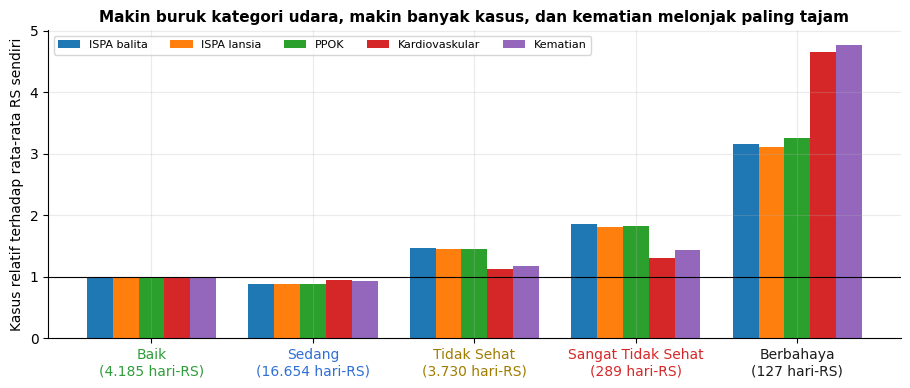

In [25]:
DR = HM.dropna(subset=["pm25"]).copy()
for o in OUTC:
    DR[o + "_rel"] = DR[o] / DR.groupby("hospital_id")[o].transform("mean")
DR["kategori"] = pd.cut(DR["pm25"], PM25_BINS, labels=ISPU_LAB)
dose = DR.groupby("kategori")[[o + "_rel" for o in OUTC]].mean()
dose.columns = [OUTC_LAB[c[:-4]] for c in dose.columns]
dose["hari-RS"] = DR.groupby("kategori").size()
display(dose)
fig, ax = plt.subplots(figsize=(11, 4))
sel = ["ISPA balita", "ISPA lansia", "PPOK", "Kardiovaskular", "Kematian"]
x = np.arange(len(ISPU_LAB)); w = 0.16
for i, s in enumerate(sel):
    ax.bar(x + (i - 2) * w, dose[s], w, label=s)
ax.axhline(1, color="k", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"{l}\n({fmt(n, 0)} hari-RS)" for l, n in zip(ISPU_LAB, dose["hari-RS"])])
for t, c in zip(ax.get_xticklabels(), ISPU_COL): t.set_color(c if c != "#f2c40f" else "#a07d00")
ax.set_ylabel("Kasus relatif terhadap rata-rata RS sendiri")
ax.set_title("Makin buruk kategori udara, makin banyak kasus, dan kematian melonjak paling tajam")
ax.legend(ncol=5, fontsize=8)
savefig("14_dosis_respons_ispu")

### 5.2 Bentuk hubungan: linear atau logaritmik?
Model Poisson gabungan (efek tetap RS, bulan, hari, suhu). Dibandingkan: PM2.5 linear vs log₂ PM2.5. AIC lebih kecil = lebih cocok.

In [26]:
base_f = "C(hospital_id) + C(bulan) + C(dow) + temp_c"
B0 = HM.dropna(subset=["pm25"]).copy()
B0["pm10u"] = B0["pm25"] / 10
rows = []
for o in OUTC:
    m_lin = smf.glm(f"{o} ~ pm10u + {base_f}", data=B0, family=sm.families.Poisson()).fit()
    m_log = smf.glm(f"{o} ~ lpm_l0 + {base_f}", data=B0, family=sm.families.Poisson()).fit()
    rows.append({"outcome": OUTC_LAB[o], "AIC linear": m_lin.aic, "AIC log": m_log.aic, "selisih (linear − log)": m_lin.aic - m_log.aic})
display(pd.DataFrame(rows).set_index("outcome").round(0))

,AIC linear,AIC log,selisih (linear − log)
outcome,,,
ISPA balita,"113,914.00","107,907.00","6,007.00"
ISPA lansia,"119,705.00","113,345.00","6,360.00"
Darurat asma,"100,038.00","96,515.00","3,524.00"
PPOK,"92,940.00","89,606.00","3,334.00"
Rawat napas umum,"167,517.00","153,247.00","14,269.00"
Kardiovaskular,"110,532.00","111,026.00",-494.00
Kematian,"75,825.00","75,756.00",68.00


**Pengecualian: kardiovaskular dan kematian.** Untuk dua outcome ini, model log tidak lebih baik daripada linear. Tabel deskriptif di 5.1 juga menunjukkan lonjakan tajam di kategori *Berbahaya*. Dicek dengan potongan PM2.5 yang lebih rinci:

In [27]:
DR["pita"] = pd.cut(DR["pm25"], [0, 55.4, 150.4, 250.4, 350, 500, np.inf],
                    labels=["≤55", "55–150", "150–250", "250–350", "350–500", ">500"])
thr = DR.groupby("pita")[["resp_admissions_under5_rel", "resp_rel", "cvd_rel", "death_rel"]].mean()
thr.columns = ["ISPA balita", "Rawat napas", "Kardiovaskular", "Kematian"]
thr["hari-RS"] = DR.groupby("pita").size()
display(thr.round(2))

,ISPA balita,Rawat napas,Kardiovaskular,Kematian,hari-RS
pita,,,,,
≤55,0.89,0.91,0.95,0.94,20839
55–150,1.47,1.36,1.12,1.18,3730
150–250,1.86,1.70,1.30,1.44,289
250–350,1.92,1.76,1.18,1.27,35
350–500,2.97,2.86,6.00,6.00,62
>500,5.00,4.26,5.93,6.31,30


Hubungan **log** jauh lebih cocok untuk hampir semua penyakit pernapasan. Artinya efek PM2.5 bersifat **relatif**: setiap kali PM2.5 **berlipat dua**, kasus naik dengan persentase yang kira-kira sama, baik dari 15 → 30 maupun dari 150 → 300. Konsekuensinya, kenaikan +10 µg/m³ di wilayah bersih jauh lebih berbahaya dibanding +10 µg/m³ di wilayah yang sudah pekat. Karena itu semua efek di bawah dilaporkan sebagai **RR per PM2.5 berlipat dua**.

### 5.2b Model ambang (*threshold*)
Untuk menangkap lonjakan di konsentrasi sangat tinggi, model log diberi tambahan suku engsel (*hinge*) `max(0, PM2.5 − T)`. Ambang T dicari dari {150, 200, 250, 300, 350, 400} dengan AIC terkecil. Suku ambang dipakai di simulasi hanya jika memperbaiki AIC > 10 dan efeknya positif.

In [28]:
TS = [150, 200, 250, 300, 350, 400]
amb_rows, AMBANG = [], {}
for o in OUTC:
    m0 = smf.glm(f"{o} ~ lpm_l0 + {base_f}", data=B0, family=sm.families.Poisson()).fit()
    best = None
    for T in TS:
        B0["h"] = np.maximum(0, B0["pm25"] - T) / 100
        m = smf.glm(f"{o} ~ lpm_l0 + h + {base_f}", data=B0, family=sm.families.Poisson()).fit()
        if best is None or m.aic < best[1].aic:
            best = (T, m)
    T, m = best
    d_aic = m0.aic - m.aic
    amb_rows.append({"outcome": OUTC_LAB[o], "ambang terbaik (µg/m³)": T, "perbaikan AIC": d_aic,
                     "RR per lipat dua (bagian log)": np.exp(m.params["lpm_l0"]),
                     "RR tambahan per +100 di atas ambang": np.exp(m.params["h"]), "p (suku ambang)": m.pvalues["h"]})
    if d_aic > 10 and m.params["h"] > 0:
        AMBANG[o] = {"T": T, "b_log": float(m.params["lpm_l0"]), "b_h": float(m.params["h"])}
display(pd.DataFrame(amb_rows).set_index("outcome").round(3))
print("Outcome yang memakai model ambang di simulasi:", [OUTC_LAB[o] for o in AMBANG])

,ambang terbaik (µg/m³),perbaikan AIC,RR per lipat dua (bagian log),RR tambahan per +100 di atas ambang,p (suku ambang)
outcome,,,,,
ISPA balita,150,591.69,1.69,0.89,0.00
ISPA lansia,150,465.32,1.64,0.91,0.00
Darurat asma,150,259.83,1.65,0.90,0.00
PPOK,150,251.92,1.69,0.90,0.00
Rawat napas umum,150,698.46,1.52,0.93,0.00
Kardiovaskular,150,"1,050.06",1.28,1.18,0.00
Kematian,150,212.07,1.34,1.14,0.00


Outcome yang memakai model ambang di simulasi: ['Kardiovaskular', 'Kematian']


**Cara membaca:** ambang terbaik untuk semua outcome jatuh di **150 µg/m³** (batas kategori *Sangat Tidak Sehat*), tetapi arahnya berbeda:
- **Pernapasan** (ISPA, asma, PPOK): suku ambang < 1 → kurva **sedikit melandai** di atas 150. Model log per RS di simulasi sudah menangkap ini karena tiap RS punya kemiringannya sendiri.
- **Kardiovaskular & kematian**: suku ambang > 1 → risiko **melonjak** di atas 150. Dua outcome ini memakai model ambang di simulasi.

### 5.3 Model dua tahap (Model M3)
**Tahap 1, per RS:** quasi-Poisson `kasus ~ log₂ PM2.5 (hari yang sama) + spline waktu (12 df, menyerap tren & musim) + suhu + hari`.
**Tahap 2:** estimasi per RS digabung dengan meta-analisis *random effects* (DerSimonian–Laird). I² menunjukkan seberapa beragam efeknya antar RS.

In [29]:
def fit_rs(g, outcome, expo, df_t=12):
    f = f"{outcome} ~ {' + '.join(expo)} + bs(t, df={df_t}) + temp_c + C(dow)"
    try:
        return smf.glm(f, data=g, family=sm.families.Poisson()).fit(scale="X2")
    except Exception:
        return None

def meta_dl(b, se):
    b, se = np.asarray(b, float), np.asarray(se, float)
    ok = np.isfinite(b) & np.isfinite(se) & (se > 0)
    b, se = b[ok], se[ok]
    w = 1 / se**2
    bf = (w * b).sum() / w.sum()
    Q = (w * (b - bf) ** 2).sum(); k = len(b)
    tau2 = max(0.0, (Q - (k - 1)) / (w.sum() - (w**2).sum() / w.sum()))
    wr = 1 / (se**2 + tau2)
    br = (wr * b).sum() / wr.sum(); ser = np.sqrt(1 / wr.sum())
    return {"b": br, "se": ser, "tau2": tau2, "I2": max(0.0, (Q - (k - 1)) / Q) if Q > 0 else 0.0, "k": k}

def rr_row(m, label):
    return {"": label, "RR per lipat dua": np.exp(m["b"]), "CI bawah": np.exp(m["b"] - 1.96 * m["se"]),
            "CI atas": np.exp(m["b"] + 1.96 * m["se"]), "I²": m["I2"], "jumlah RS": m["k"]}

stage1 = []
for hid, g in HM.dropna(subset=["lpm_l0"]).groupby("hospital_id"):
    for o in OUTC:
        m = fit_rs(g, o, ["lpm_l0"])
        if m is not None:
            stage1.append({"hospital_id": hid, "code": g.code.iloc[0], "outcome": o, "b": m.params["lpm_l0"],
                           "se": m.bse["lpm_l0"], "sd_lpm": g.lpm_l0.std()})
stage1 = pd.DataFrame(stage1)
pooled = {o: meta_dl(g.b, g.se) for o, g in stage1.groupby("outcome")}
res_main = pd.DataFrame([rr_row(pooled[o], OUTC_LAB[o]) for o in OUTC]).set_index("")
display(res_main.round(3))

,RR per lipat dua,CI bawah,CI atas,I²,jumlah RS
,,,,,
ISPA balita,1.56,1.42,1.71,0.98,25
ISPA lansia,1.51,1.39,1.64,0.98,25
Darurat asma,1.61,1.48,1.75,0.97,25
PPOK,1.51,1.39,1.65,0.97,25
Rawat napas umum,1.42,1.33,1.52,0.99,25
Kardiovaskular,1.19,1.14,1.24,0.91,25
Kematian,1.27,1.19,1.36,0.82,25


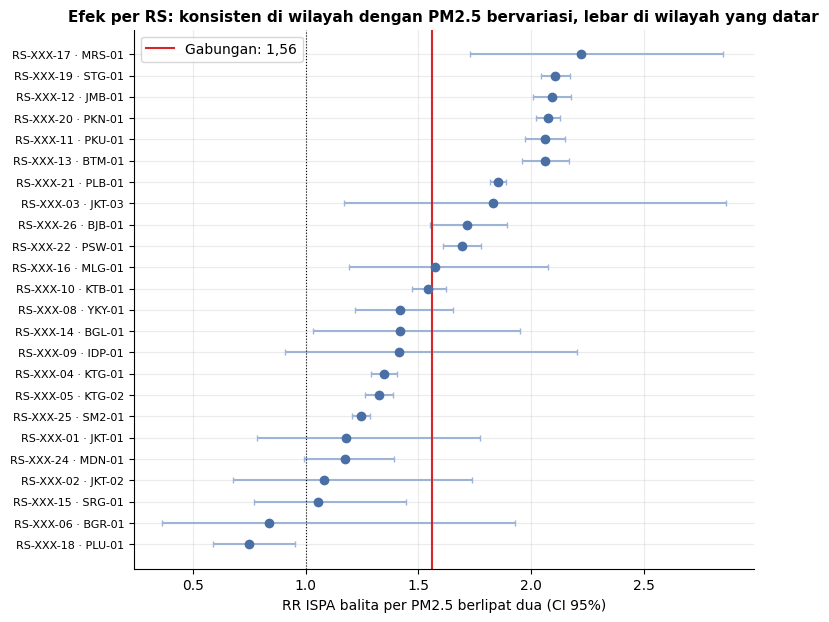

RS dengan CI sangat lebar (tidak ditampilkan): ['RS-XXX-07']


In [30]:
fo = "resp_admissions_under5"
s1 = stage1[stage1.outcome == fo].copy()
s1["rr"], s1["lo"], s1["hi"] = np.exp(s1.b), np.exp(s1.b - 1.96 * s1.se), np.exp(s1.b + 1.96 * s1.se)
s1 = s1[s1.hi < 5].sort_values("rr")
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(s1))
ax.errorbar(s1.rr, y, xerr=[s1.rr - s1.lo, s1.hi - s1.rr], fmt="o", color="#4a6fa5", ecolor="#9db4d6", capsize=2)
pr = pooled[fo]
ax.axvline(np.exp(pr["b"]), color="#d62728", lw=1.5, label=f"Gabungan: {fmt(np.exp(pr['b']), 2)}")
ax.axvline(1, color="k", lw=0.8, ls=":")
ax.set_yticks(y); ax.set_yticklabels([f"{h} · {c}" for h, c in zip(s1.hospital_id, s1.code)], fontsize=8)
ax.set_xlabel("RR ISPA balita per PM2.5 berlipat dua (CI 95%)")
ax.set_title("Efek per RS: konsisten di wilayah dengan PM2.5 bervariasi, lebar di wilayah yang datar")
ax.legend()
savefig("15_forest_rs")
print("RS dengan CI sangat lebar (tidak ditampilkan):", sorted(set(stage1[stage1.outcome == fo].hospital_id) - set(s1.hospital_id)))

### 5.4 Efek jeda & uji plasebo
Setiap lag diuji terpisah: **lag k** = PM2.5 k hari *sebelum* kasus, **lead k** = PM2.5 k hari *sesudah* kasus (plasebo: PM2.5 masa depan secara logika tidak bisa menyebabkan kasus hari ini). Kalau efek lead hampir sama besar dengan efek lag, berarti yang terlihat hanyalah autokorelasi asap, bukan efek jeda.
Lalu semua lag dan lead dimasukkan **bersamaan** dalam satu model per RS supaya terlihat lag mana yang benar-benar bertahan.

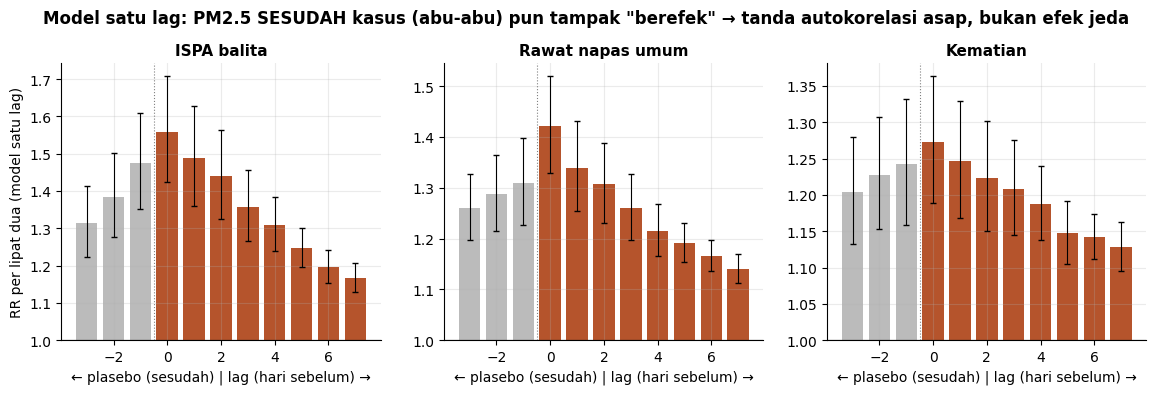

outcome,ISPA balita,Kematian,Rawat napas umum
variabel,,,
lag 0,1.54,1.28,1.44
lag 1,0.99,0.97,1.01
lag 2,1.02,1.03,1.00
lag 3,0.99,0.97,0.99
plasebo +1,1.03,1.00,1.00
plasebo +2,0.99,1.01,1.00


,outcome,variabel,RR,CI bawah,CI atas
0,ISPA balita,lag 0,1.54,1.38,1.72
1,ISPA balita,lag 1,0.99,0.96,1.03
2,ISPA balita,lag 2,1.02,0.98,1.05
3,ISPA balita,lag 3,0.99,0.97,1.01
4,ISPA balita,plasebo +1,1.03,0.99,1.07
5,ISPA balita,plasebo +2,0.99,0.96,1.02
6,Rawat napas umum,lag 0,1.44,1.33,1.55
7,Rawat napas umum,lag 1,1.01,0.98,1.03
8,Rawat napas umum,lag 2,1.00,0.98,1.02
9,Rawat napas umum,lag 3,0.99,0.97,1.00


In [31]:
lag_cols = {**{-k: f"lpm_f{k}" for k in range(1, 4)}, **{k: f"lpm_l{k}" for k in range(0, 8)}}
lag_out = ["resp_admissions_under5", "resp", "death"]
lag_res = []
for o in lag_out:
    for k, col in sorted(lag_cols.items()):
        bs_, ses_ = [], []
        for hid, g in HM.dropna(subset=[col]).groupby("hospital_id"):
            m = fit_rs(g, o, [col])
            if m is not None:
                bs_.append(m.params[col]); ses_.append(m.bse[col])
        mm = meta_dl(bs_, ses_)
        lag_res.append({"outcome": OUTC_LAB[o], "lag": k, "RR": np.exp(mm["b"]),
                        "lo": np.exp(mm["b"] - 1.96 * mm["se"]), "hi": np.exp(mm["b"] + 1.96 * mm["se"])})
lag_res = pd.DataFrame(lag_res)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, (o, g) in zip(axes, lag_res.groupby("outcome", sort=False)):
    col = np.where(g.lag < 0, "#bbbbbb", "#b5542c")
    ax.bar(g.lag, g.RR - 1, bottom=1, color=col)
    ax.errorbar(g.lag, g.RR, yerr=[g.RR - g.lo, g.hi - g.RR], fmt="none", ecolor="k", capsize=2, lw=0.8)
    ax.axhline(1, color="k", lw=0.8); ax.axvline(-0.5, color="grey", ls=":", lw=0.8)
    ax.set_title(o); ax.set_xlabel("← plasebo (sesudah) | lag (hari sebelum) →")
axes[0].set_ylabel("RR per lipat dua (model satu lag)")
plt.suptitle("Model satu lag: PM2.5 SESUDAH kasus (abu-abu) pun tampak \"berefek\" → tanda autokorelasi asap, bukan efek jeda", y=1.03, fontweight="bold")
savefig("16_lag_plasebo")

multi = ["lpm_l0", "lpm_l1", "lpm_l2", "lpm_l3", "lpm_f1", "lpm_f2"]
mrows = []
for o in lag_out:
    coefs = {c: ([], []) for c in multi}
    for hid, g in HM.dropna(subset=multi).groupby("hospital_id"):
        m = fit_rs(g, o, multi)
        if m is not None:
            for c in multi:
                coefs[c][0].append(m.params[c]); coefs[c][1].append(m.bse[c])
    for c in multi:
        mm = meta_dl(*coefs[c])
        mrows.append({"outcome": OUTC_LAB[o], "variabel": c.replace("lpm_l", "lag ").replace("lpm_f", "plasebo +"),
                      "RR": np.exp(mm["b"]), "CI bawah": np.exp(mm["b"] - 1.96 * mm["se"]), "CI atas": np.exp(mm["b"] + 1.96 * mm["se"])})
multi_res = pd.DataFrame(mrows)
display(multi_res.pivot(index="variabel", columns="outcome", values="RR").round(3))
display(multi_res.round(3))

### 5.5 Balita vs lansia
Dibandingkan dari tiga sisi: kepekaan relatif (RR), beban absolut, dan bagaimana rasio lansia/balita berubah saat udara memburuk.

In [32]:
pb, pl = pooled["resp_admissions_under5"], pooled["resp_admissions_over60"]
z = (pb["b"] - pl["b"]) / np.sqrt(pb["se"] ** 2 + pl["se"] ** 2)
print(f"RR balita {np.exp(pb['b']):.3f} vs lansia {np.exp(pl['b']):.3f} | selisih z = {z:.2f}, p = {2 * (1 - stats.norm.cdf(abs(z))):.3f}")
print("Total kasus (semua RS):", {OUTC_LAB[o]: int(hl[o].sum()) for o in ["resp_admissions_under5", "resp_admissions_over60"]})
rat = DR.groupby("kategori")[["resp_admissions_over60", "resp_admissions_under5"]].sum()
rat["rasio lansia/balita"] = rat.resp_admissions_over60 / rat.resp_admissions_under5
display(rat)

RR balita 1.559 vs lansia 1.508 | selisih z = 0.53, p = 0.596
Total kasus (semua RS): {'ISPA balita': 186191, 'ISPA lansia': 225140}


,resp_admissions_over60,resp_admissions_under5,rasio lansia/balita
kategori,,,
Baik,"17,186.00","13,345.00",1.29
Sedang,"129,035.00","105,569.00",1.22
Tidak Sehat,"62,655.00","52,679.00",1.19
Sangat Tidak Sehat,"5,247.00","4,579.00",1.15
Berbahaya,"3,971.00","3,522.00",1.13


### 5.5b Uji sensitivitas
Apakah kesimpulan berubah kalau spesifikasi model diubah? RR per lipat dua (gabungan dua tahap) dihitung ulang dengan 8 variasi: kontrol musim yang lebih longgar/ketat, dummy bulan, mengeluarkan RS yang bermasalah, dan paparan rata-rata 2 hari.

outcome,ISPA balita,ISPA lansia,Kematian
spesifikasi,,,
Dummy bulan & tahun,1.59,1.51,1.40
Paparan rata-rata hari ini & kemarin,1.58,1.53,1.28
Spline waktu 20 df (kontrol musim ketat),1.57,1.51,1.29
Spline waktu 6 df (kontrol musim longgar),1.47,1.42,1.21
"Tanpa RS-05 (KTG-02, kembar KTG-01)",1.58,1.52,1.26
Tanpa RS-24–26 (profil kasus berbeda),1.61,1.56,1.34
"Tanpa stasiun banyak imputasi (MDN, PLB, SM2)",1.59,1.54,1.32
Utama (spline waktu 12 df),1.56,1.51,1.27


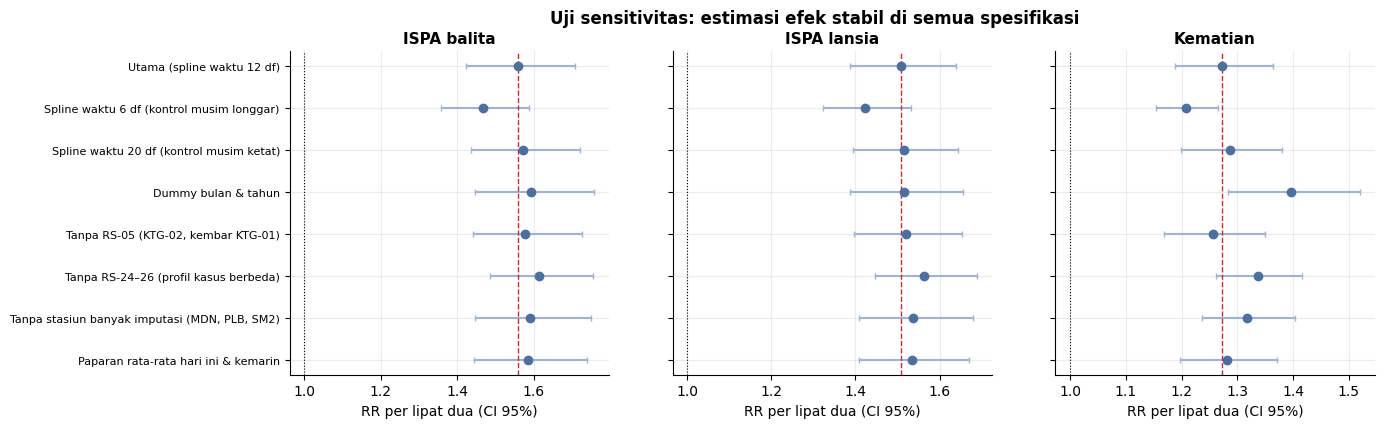

Rentang RR antar spesifikasi: {'ISPA balita': (np.float64(1.47), np.float64(1.61)), 'ISPA lansia': (np.float64(1.42), np.float64(1.56)), 'Kematian': (np.float64(1.21), np.float64(1.4))}


In [33]:
HM["lpm_avg01"] = np.log2(((HM["pm"] + HM["pm_l1"]) / 2).clip(lower=1))
def pooled_rr(data, outcome, spec="bs12", expo="lpm_l0"):
    b_, s_ = [], []
    for hid, g in data.dropna(subset=[expo]).groupby("hospital_id"):
        f = (f"{outcome} ~ {expo} + bs(t, df={int(spec[2:])}) + temp_c + C(dow)" if spec.startswith("bs")
             else f"{outcome} ~ {expo} + C(bulan) + C(tahun) + temp_c + C(dow)")
        try:
            m = smf.glm(f, data=g, family=sm.families.Poisson()).fit(scale="X2")
        except Exception:
            continue
        b_.append(m.params[expo]); s_.append(m.bse[expo])
    return meta_dl(b_, s_)
SENS = {
    "Utama (spline waktu 12 df)": (HM, "bs12", "lpm_l0"),
    "Spline waktu 6 df (kontrol musim longgar)": (HM, "bs6", "lpm_l0"),
    "Spline waktu 20 df (kontrol musim ketat)": (HM, "bs20", "lpm_l0"),
    "Dummy bulan & tahun": (HM, "bulan", "lpm_l0"),
    "Tanpa RS-05 (KTG-02, kembar KTG-01)": (HM[HM.hospital_id != "RS-XXX-05"], "bs12", "lpm_l0"),
    "Tanpa RS-24–26 (profil kasus berbeda)": (HM[~HM.hospital_id.isin(["RS-XXX-24", "RS-XXX-25", "RS-XXX-26"])], "bs12", "lpm_l0"),
    "Tanpa stasiun banyak imputasi (MDN, PLB, SM2)": (HM[~HM.hospital_id.isin(["RS-XXX-24", "RS-XXX-21", "RS-XXX-25"])], "bs12", "lpm_l0"),
    "Paparan rata-rata hari ini & kemarin": (HM, "bs12", "lpm_avg01"),
}
sens_rows = []
for nama, (dat, spec, expo) in SENS.items():
    for o in ["resp_admissions_under5", "resp_admissions_over60", "death"]:
        mm = pooled_rr(dat, o, spec, expo)
        sens_rows.append({"spesifikasi": nama, "outcome": OUTC_LAB[o], "RR": np.exp(mm["b"]),
                          "lo": np.exp(mm["b"] - 1.96 * mm["se"]), "hi": np.exp(mm["b"] + 1.96 * mm["se"])})
sens = pd.DataFrame(sens_rows)
display(sens.pivot(index="spesifikasi", columns="outcome", values="RR").round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
names = list(SENS)
for ax, (o, g) in zip(axes, sens.groupby("outcome", sort=False)):
    g = g.set_index("spesifikasi").reindex(names)
    y = np.arange(len(g))[::-1]
    ax.errorbar(g.RR, y, xerr=[g.RR - g.lo, g.hi - g.RR], fmt="o", color="#4a6fa5", ecolor="#9db4d6", capsize=2)
    ax.axvline(g.RR.iloc[0], color="#d62728", lw=1, ls="--"); ax.axvline(1, color="k", lw=0.8, ls=":")
    ax.set_title(o); ax.set_xlabel("RR per lipat dua (CI 95%)")
axes[0].set_yticks(np.arange(len(names))[::-1]); axes[0].set_yticklabels(names, fontsize=8)
plt.suptitle("Uji sensitivitas: estimasi efek stabil di semua spesifikasi", fontweight="bold")
savefig("16b_sensitivitas")
rng = sens.groupby("outcome").RR.agg(["min", "max"])
print("Rentang RR antar spesifikasi:", {k: (round(r["min"], 2), round(r["max"], 2)) for k, r in rng.iterrows()})

### 5.6 Model ML (LightGBM Poisson) vs model statistik
Pertanyaan praktis: model mana yang lebih layak dipakai untuk **simulasi**? Keduanya dilatih pada 2024–2025 dan diuji pada 2026 (Jan–14 Okt), termasuk episode kabut asap ekstrem Kalteng 2026 yang **melebihi** rentang data latih.
- **ML:** LightGBM objektif Poisson. Fitur: RS, PM2.5 hari ini & 1–2 hari sebelumnya, rata-rata 7 hari, suhu, kelembapan, hari, bulan, musim (sin/cos).
- **Statistik:** GLM Poisson dengan efek tetap RS, kemiringan log₂ PM2.5 per RS, bulan, hari, suhu.

In [34]:
HM["dow_i"] = HM["date"].dt.dayofweek
HM["doy_sin"] = np.sin(2 * np.pi * HM.date.dt.dayofyear / 365.25)
HM["doy_cos"] = np.cos(2 * np.pi * HM.date.dt.dayofyear / 365.25)
HM["rs"] = HM["hospital_id"].astype("category")
FML = ["rs", "pm_l0", "pm_l1", "pm_l2", "pm_ma7", "temp_c", "rhum_pct", "dow_i", "bulan", "doy_sin", "doy_cos"]
MLD = HM.dropna(subset=["pm_l0", "pm_l1", "pm_l2", "pm_ma7", "lpm_l1", "lpm_l2"]).copy()
trn, tst = MLD[MLD.tahun <= 2025], MLD[MLD.tahun == 2026].copy()
max_train_pm = trn.groupby("hospital_id")["pm_l0"].max()
tst["ekstrem"] = tst["pm_l0"] > tst["hospital_id"].map(max_train_pm)
print(f"Hari uji: {len(tst)} | hari 'ekstrem' (PM2.5 di atas maksimum data latih RS-nya): {int(tst.ekstrem.sum())}")
ML_OUT = ["resp_admissions_under5", "resp_admissions_over60", "resp", "death"]
models_ml, perf = {}, []
glm_f = "C(hospital_id) + C(hospital_id):lpm_l0 + lpm_l1 + lpm_l2 + C(bulan) + C(dow) + temp_c"
for o in ML_OUT:
    ml = lgb.LGBMRegressor(objective="poisson", n_estimators=700, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.9, random_state=42, verbose=-1)
    ml.fit(trn[FML], trn[o])
    models_ml[o] = ml
    gl = smf.glm(f"{o} ~ {glm_f}", data=trn, family=sm.families.Poisson()).fit()
    p_ml, p_gl = ml.predict(tst[FML]), gl.predict(tst)
    tst[f"{o}_ml"], tst[f"{o}_glm"] = p_ml, p_gl
    for nama, p in [("LightGBM", p_ml), ("GLM log-PM", p_gl)]:
        for sub, msk in [("Semua hari 2026", np.ones(len(tst), bool)), ("Hari ekstrem", tst.ekstrem.values)]:
            perf.append({"outcome": OUTC_LAB[o], "model": nama, "subset": sub,
                         "deviance Poisson": mean_poisson_deviance(tst[o][msk], np.clip(p[msk], 1e-6, None)),
                         "MAE": mean_absolute_error(tst[o][msk], p[msk]), "R²": r2_score(tst[o][msk], p[msk])})
perf = pd.DataFrame(perf)
display(perf.pivot_table(index=["outcome", "subset"], columns="model", values=["R²", "MAE"]).round(3))

Hari uji: 7074 | hari 'ekstrem' (PM2.5 di atas maksimum data latih RS-nya): 571


MAE                  R²         
model                            GLM log-PM LightGBM GLM log-PM LightGBM
outcome          subset                                                 
ISPA balita      Hari ekstrem          2.60     3.34       0.81     0.44
                 Semua hari 2026       1.51     1.56       0.89     0.82
ISPA lansia      Hari ekstrem          3.00     3.83       0.80     0.40
                 Semua hari 2026       1.70     1.73       0.89     0.82
Kematian         Hari ekstrem          2.00     2.40       0.23    -0.14
                 Semua hari 2026       0.92     0.96       0.41     0.24
Rawat napas umum Hari ekstrem          8.30    13.38       0.84     0.36
                 Semua hari 2026       3.91     4.16       0.93     0.83

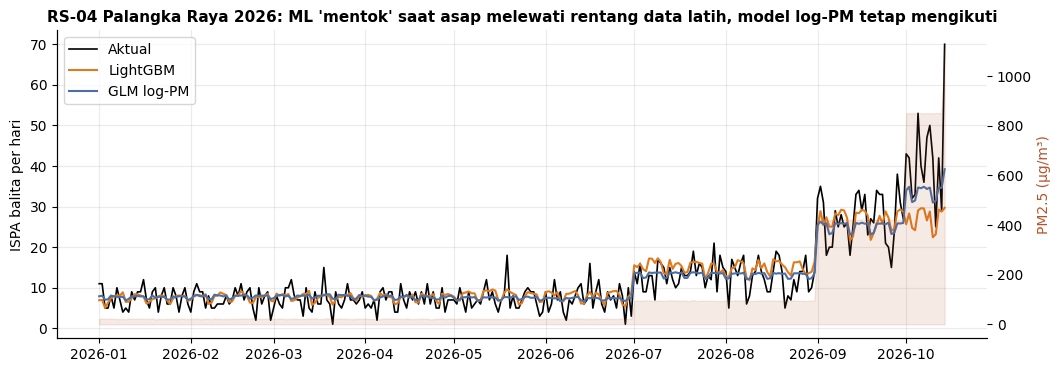

In [35]:
demo = tst[tst.hospital_id == "RS-XXX-04"].sort_values("date")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(demo.date, demo.resp_admissions_under5, color="k", lw=1.2, label="Aktual")
ax.plot(demo.date, demo.resp_admissions_under5_ml, color="#e07a1f", lw=1.5, label="LightGBM")
ax.plot(demo.date, demo.resp_admissions_under5_glm, color="#4a6fa5", lw=1.5, label="GLM log-PM")
ax2 = ax.twinx(); ax2.fill_between(demo.date, demo.pm25, color="#b5542c", alpha=0.12); ax2.set_ylabel("PM2.5 (µg/m³)", color="#b5542c"); ax2.grid(False)
ax.set_ylabel("ISPA balita per hari"); ax.legend(loc="upper left")
ax.set_title("RS-04 Palangka Raya 2026: ML 'mentok' saat asap melewati rentang data latih, model log-PM tetap mengikuti")
savefig("17_ml_vs_glm")

### 5.7 Simulasi dampak kesehatan
Mesin simulasi memakai **model dua tahap** karena (a) mampu mengikuti kondisi ekstrem di luar data latih, (b) efeknya bisa dijelaskan, dan (c) estimasi per RS distabilkan dengan *empirical Bayes shrinkage* (RS dengan data lemah ditarik ke efek gabungan).

Rumus: kasus skenario = kasus aktual × (PM2.5 skenario / PM2.5 aktual)^γ, dengan γ = koefisien log₂ / ln 2. Ini pendekatan standar *health impact assessment*: perubahan relatif diterapkan pada kasus yang benar-benar tercatat. Untuk outcome yang terbukti punya **ambang** (5.2b), faktor pengali memakai model ambang gabungan.

In [36]:
shr = []
for o, gp in stage1.groupby("outcome"):
    pr = pooled[o]
    w = pr["tau2"] / (pr["tau2"] + gp["se"] ** 2)
    shr.append(pd.DataFrame({"hospital_id": gp.hospital_id, "outcome": o, "b_shrunk": pr["b"] + w * (gp["b"] - pr["b"])}))
B_RS = pd.concat(shr).pivot(index="hospital_id", columns="outcome", values="b_shrunk")

def batas(c):  return lambda pm: np.minimum(pm, c)
def kali(f):   return lambda pm: pm * f
def tetap(v):  return lambda pm: pm * 0 + v

def simulasi_dampak(hospital_id, skenario, outcomes=OUTC, mulai=None, selesai=None):
    """Estimasi perubahan kasus di satu RS bila PM2.5 harian diganti `skenario(pm_aktual)`."""
    g = HM[(HM.hospital_id == hospital_id)].dropna(subset=["pm25"])
    if mulai: g = g[g.date >= mulai]
    if selesai: g = g[g.date <= selesai]
    pm_obs = g["pm"]; pm_new = np.clip(skenario(pm_obs), 1, None)
    rows = []
    for o in outcomes:
        if o in AMBANG:   # model ambang gabungan (kardiovaskular, kematian, ...)
            a = AMBANG[o]
            fac = np.exp(a["b_log"] * (np.log2(pm_new) - np.log2(pm_obs))
                         + a["b_h"] * (np.maximum(0, pm_new - a["T"]) - np.maximum(0, pm_obs - a["T"])) / 100)
        else:             # model log per RS (shrinkage)
            fac = (pm_new / pm_obs) ** (B_RS.loc[hospital_id, o] / np.log(2))
        y_new = g[o] * fac
        rows.append({"outcome": OUTC_LAB[o], "kasus aktual": g[o].sum(), "kasus skenario": y_new.sum(),
                     "selisih": y_new.sum() - g[o].sum(), "perubahan %": 100 * (y_new.sum() / g[o].sum() - 1)})
    return pd.DataFrame(rows).set_index("outcome")

print("Contoh 1 · RS-04 Palangka Raya, musim asap 2026 (1 Jul–14 Okt): PM2.5 dibatasi maks. 55 (baku mutu harian)")
display(simulasi_dampak("RS-XXX-04", batas(55), mulai="2026-07-01").round(1))
print("Contoh 2 · RS-21 Palembang, tahun 2025: PM2.5 musim asap dibatasi maks. 150,4 (cegah kategori Sangat Tidak Sehat)")
display(simulasi_dampak("RS-XXX-21", batas(150.4), mulai="2025-01-01", selesai="2025-12-31").round(1))
print("Contoh 3 · RS-02 Marunda (kronis), tahun 2025: emisi ditekan sehingga PM2.5 turun 30% setiap hari")
display(simulasi_dampak("RS-XXX-02", kali(0.7), mulai="2025-01-01", selesai="2025-12-31").round(1))

Contoh 1 · RS-04 Palangka Raya, musim asap 2026 (1 Jul–14 Okt): PM2.5 dibatasi maks. 55 (baku mutu harian)


,kasus aktual,kasus skenario,selisih,perubahan %
outcome,,,,
ISPA balita,"2,198.00","1,148.50","-1,049.50",-47.70
ISPA lansia,"2,497.00","1,304.50","-1,192.50",-47.80
Darurat asma,"1,193.00",710.80,-482.20,-40.40
PPOK,"1,018.00",477.60,-540.40,-53.10
Rawat napas umum,"9,279.00","5,137.80","-4,141.20",-44.60
Kardiovaskular,"2,510.00",919.50,"-1,590.50",-63.40
Kematian,773.00,262.30,-510.70,-66.10


Contoh 2 · RS-21 Palembang, tahun 2025: PM2.5 musim asap dibatasi maks. 150,4 (cegah kategori Sangat Tidak Sehat)


,kasus aktual,kasus skenario,selisih,perubahan %
outcome,,,,
ISPA balita,"4,605.00","4,486.20",-118.80,-2.60
ISPA lansia,"5,465.00","5,331.90",-133.10,-2.40
Darurat asma,"2,624.00","2,559.20",-64.80,-2.50
PPOK,"2,984.00","2,911.60",-72.40,-2.40
Rawat napas umum,"15,666.00","15,370.90",-295.10,-1.90
Kardiovaskular,"4,055.00","4,007.50",-47.50,-1.20
Kematian,"1,027.00","1,013.10",-13.90,-1.40


Contoh 3 · RS-02 Marunda (kronis), tahun 2025: emisi ditekan sehingga PM2.5 turun 30% setiap hari


,kasus aktual,kasus skenario,selisih,perubahan %
outcome,,,,
ISPA balita,"5,057.00","4,346.30",-710.70,-14.10
ISPA lansia,"6,403.00","5,693.80",-709.20,-11.10
Darurat asma,"2,866.00","2,328.20",-537.80,-18.80
PPOK,"2,242.00","1,942.40",-299.60,-13.40
Rawat napas umum,"20,267.00","18,317.30","-1,949.70",-9.60
Kardiovaskular,"3,797.00","3,347.20",-449.80,-11.80
Kematian,"1,403.00","1,206.10",-196.90,-14.00


In [37]:
skens = {"Batas 150,4 (hindari 'Sangat Tidak Sehat')": batas(150.4), "Batas 55 (baku mutu harian PP 22/2021)": batas(55),
         "Batas 15 (pedoman harian WHO)": batas(15)}
tot = []
for nama, f in skens.items():
    acc = None
    for hid in B_RS.index:
        r = simulasi_dampak(hid, f, outcomes=["resp_admissions_under5", "resp_admissions_over60", "death"], mulai="2025-01-01", selesai="2025-12-31")
        acc = r if acc is None else acc.add(r)
    acc["perubahan %"] = 100 * (acc["kasus skenario"] / acc["kasus aktual"] - 1)
    acc["skenario"] = nama
    tot.append(acc.reset_index())
tot = pd.concat(tot)
print("Beban teratribusi PM2.5 di 25 RS, tahun 2025 (kasus yang diperkirakan tidak terjadi bila PM2.5 tidak melewati batas):")
display(tot.pivot(index="skenario", columns="outcome", values="selisih").round(0))
display(tot.pivot(index="skenario", columns="outcome", values="perubahan %").round(1))

Beban teratribusi PM2.5 di 25 RS, tahun 2025 (kasus yang diperkirakan tidak terjadi bila PM2.5 tidak melewati batas):


outcome,ISPA balita,ISPA lansia,Kematian
skenario,,,
Batas 15 (pedoman harian WHO),"-30,025.00","-34,331.00","-5,708.00"
"Batas 150,4 (hindari 'Sangat Tidak Sehat')",-146.00,-165.00,-35.00
Batas 55 (baku mutu harian PP 22/2021),"-5,973.00","-6,661.00",-695.00


outcome,ISPA balita,ISPA lansia,Kematian
skenario,,,
Batas 15 (pedoman harian WHO),-47.10,-44.30,-31.60
"Batas 150,4 (hindari 'Sangat Tidak Sehat')",-0.20,-0.20,-0.20
Batas 55 (baku mutu harian PP 22/2021),-9.40,-8.60,-3.80


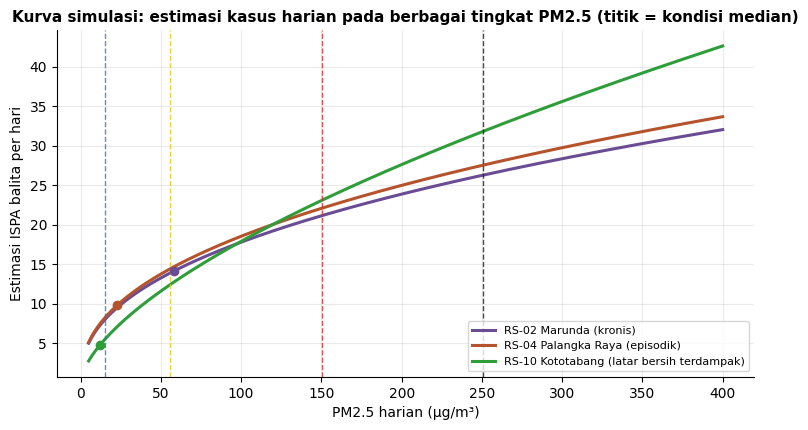

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pm_grid = np.linspace(5, 400, 200)
for hid, lab, c in [("RS-XXX-02", "RS-02 Marunda (kronis)", "#6a4c93"), ("RS-XXX-04", "RS-04 Palangka Raya (episodik)", "#b5542c"),
                    ("RS-XXX-10", "RS-10 Kototabang (latar bersih terdampak)", "#2e9d3a")]:
    g = HM[(HM.hospital_id == hid)].dropna(subset=["pm25"])
    gam = B_RS.loc[hid, "resp_admissions_under5"] / np.log(2)
    ref = g.pm.median(); base_ = g.resp_admissions_under5.mean()
    ax.plot(pm_grid, base_ * (pm_grid / ref) ** gam, color=c, lw=2.2, label=lab)
    ax.scatter([ref], [base_], color=c, zorder=3)
for x0, c in zip([15.5, 55.4, 150.4, 250.4], ISPU_COL[1:]):
    ax.axvline(x0, color=c, lw=1, ls="--", alpha=0.8)
ax.set_xlabel("PM2.5 harian (µg/m³)"); ax.set_ylabel("Estimasi ISPA balita per hari")
ax.set_title("Kurva simulasi: estimasi kasus harian pada berbagai tingkat PM2.5 (titik = kondisi median)")
ax.legend(fontsize=8)
savefig("18_kurva_simulasi")

**Cek konsistensi dengan ML.** Untuk skenario di dalam rentang data latih (2025, batas 55), hasil simulasi model statistik dibandingkan dengan simulasi LightGBM (fitur PM diganti nilai skenario).

In [39]:
def sim_ml(hospital_id, outcome, cap, mulai, selesai):
    g = HM[HM.hospital_id == hospital_id].sort_values("date").copy()
    g["pm_cap"] = np.minimum(g["pm"], cap)
    g2 = g.copy()
    g2["pm_l0"] = g["pm_cap"]; g2["pm_l1"] = g["pm_cap"].shift(1); g2["pm_l2"] = g["pm_cap"].shift(2)
    g2["pm_ma7"] = g["pm_cap"].rolling(7, min_periods=4).mean()
    msk = (g.date >= mulai) & (g.date <= selesai) & g[["pm_l0", "pm_l1", "pm_l2", "pm_ma7"]].notna().all(axis=1)
    base_ = models_ml[outcome].predict(g.loc[msk, FML]).sum()
    new = models_ml[outcome].predict(g2.loc[msk, FML]).sum()
    return 100 * (new / base_ - 1)
cmp_rows = []
for hid in ["RS-XXX-21", "RS-XXX-04", "RS-XXX-11", "RS-XXX-25"]:
    for o in ["resp_admissions_under5", "death"]:
        stat = simulasi_dampak(hid, batas(55), outcomes=[o], mulai="2025-01-01", selesai="2025-12-31")["perubahan %"].iloc[0]
        cmp_rows.append({"RS": hid, "outcome": OUTC_LAB[o], "Model statistik (%)": stat,
                         "LightGBM (%)": sim_ml(hid, o, 55, "2025-01-01", "2025-12-31")})
display(pd.DataFrame(cmp_rows).round(1))

,RS,outcome,Model statistik (%),LightGBM (%)
0,RS-XXX-21,ISPA balita,-28.80,-27.70
1,RS-XXX-21,Kematian,-13.30,-14.80
2,RS-XXX-04,ISPA balita,-8.50,-10.50
3,RS-XXX-04,Kematian,-8.20,-10.30
4,RS-XXX-11,ISPA balita,-20.80,-16.80
5,RS-XXX-11,Kematian,-6.70,-8.50
6,RS-XXX-25,ISPA balita,-9.80,-3.90
7,RS-XXX-25,Kematian,-11.00,-2.80


### 5.8 Beban kronis antar RS (ekologis)
Efek harian tidak bisa diukur di RS yang PM2.5-nya hampir konstan (Bogor, Jakarta). Untuk krisis kronis, perbandingan dilakukan **antar RS**: apakah RS di wilayah dengan PM2.5 rata-rata lebih tinggi menangani lebih banyak kasus napas per tempat tidur? RS Tipe A (rujukan besar) dan RS-24–27 (profil kasus berbeda) dikeluarkan. Ini analisis ekologis: hanya menunjukkan pola antar wilayah, bukan bukti per individu.

Spearman PM2.5 rata-rata vs kasus napas per 100 TT: rho = 0.95, p = 0.0000, n = 21


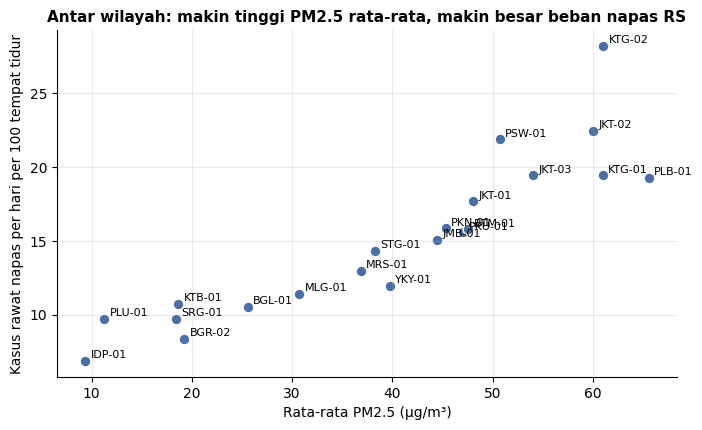

In [40]:
eco = HM.dropna(subset=["pm25"]).groupby("hospital_id").agg(pm25=("pm25", "mean"), resp=("resp", "mean"),
        bed=("kapasitas_tempat_tidur", "first"), kelas=("kelas_faskes", "first"), code=("code", "first"))
eco["resp_per100"] = 100 * eco.resp / eco.bed
eco_v = eco[~eco.kelas.str.startswith("Tipe A") & ~eco.index.isin(["RS-XXX-24", "RS-XXX-25", "RS-XXX-26", "RS-XXX-27"])]
rho, p = stats.spearmanr(eco_v.pm25, eco_v.resp_per100)
print(f"Spearman PM2.5 rata-rata vs kasus napas per 100 TT: rho = {rho:.2f}, p = {p:.4f}, n = {len(eco_v)}")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(eco_v.pm25, eco_v.resp_per100, s=60, color="#4a6fa5", edgecolor="white")
for h, r in eco_v.iterrows():
    ax.annotate(r.code, (r.pm25, r.resp_per100), xytext=(4, 2), textcoords="offset points", fontsize=8)
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)"); ax.set_ylabel("Kasus rawat napas per hari per 100 tempat tidur")
ax.set_title("Antar wilayah: makin tinggi PM2.5 rata-rata, makin besar beban napas RS")
savefig("19_ekologis")

---
## 6. Q5 · Kecukupan Jaringan Pemantauan
**Pertanyaan:** Apakah jaringan pemantauan saat ini cukup andal untuk melihat masalahnya, dan di mana perlu perbaikan atau titik baru?

Dinilai dari tiga hal: **keandalan data** tiap stasiun (dibandingkan dengan status di metadata), **redundansi** penempatan, dan **matriks prioritas** (risiko polusi × keandalan data).

In [41]:
hv = daily[daily.date >= "2024-01-01"].groupby("code").pm25.count() / 1018 * 100
sc = clean_log[["status_metadata", "satuan_asli", "SUSPECT_dipakai", "sel_teks_error", "sel_sentinel",
                "baris_sensor_beku", "baris_pm25>pm10", "jam_pm25_diinterpolasi"]].copy()
sc["hari_valid_%"] = hv.reindex(sc.index).fillna(0)
sc["imputasi_%"] = 100 * sc["jam_pm25_diinterpolasi"] / EXPECTED_H
def grade(r):
    if r["hari_valid_%"] >= 95 and r["imputasi_%"] < 5: return "A"
    if r["hari_valid_%"] >= 90: return "B"
    if r["hari_valid_%"] >= 75: return "C"
    if r["hari_valid_%"] >= 25: return "D"
    return "E"
sc["grade"] = sc.apply(grade, axis=1)
def masalah(r):
    m = []
    if r["sel_teks_error"] > 0: m.append("teks error")
    if r["sel_sentinel"] > 0: m.append("kode sentinel")
    if not r["SUSPECT_dipakai"] and r.name not in ("BJB-01", "PSW-01"): m.append("SUSPECT tidak layak")
    if r["baris_sensor_beku"] > 0: m.append(f"sensor beku {r['baris_sensor_beku']:,} jam")
    if r["baris_pm25>pm10"] > 0: m.append("PM2.5 > PM10")
    if r["imputasi_%"] >= 10: m.append(f"banyak jam hilang ({r['imputasi_%']:.0f}% diinterpolasi)")
    if r["satuan_asli"] == "ppm": m.append("satuan ppm")
    return ", ".join(m) if m else "—"
sc["masalah"] = sc.apply(masalah, axis=1)
sc["kategori"] = np.select(
    [sc.status_metadata != "Active", (sc.status_metadata == "Active") & (sc.grade.isin(["C", "D", "E"]) | (sc.baris_sensor_beku > 0))],
    ["Diakui metadata", "TERSEMBUNYI (status Active)"], "Andal")
display(sc.sort_values(["grade", "hari_valid_%"], ascending=[False, True])[["status_metadata", "grade", "hari_valid_%", "imputasi_%", "kategori", "masalah"]])
print(sc.groupby("kategori").size().to_dict())

,status_metadata,grade,hari_valid_%,imputasi_%,kategori,masalah
stasiun,,,,,,
JMB-02,Defective,E,0.00,0.03,Diakui metadata,"teks error, kode sentinel, SUSPECT tidak layak"
MER-01,Intermittent,E,0.98,2.85,Diakui metadata,SUSPECT tidak layak
BJB-01,Active,D,69.94,0.00,TERSEMBUNYI (status Active),"sensor beku 7,329 jam, satuan ppm"
SM2-01,Active,C,87.33,7.85,TERSEMBUNYI (status Active),"kode sentinel, SUSPECT tidak layak"
MDN-01,Intermittent,B,97.25,27.25,Diakui metadata,"SUSPECT tidak layak, banyak jam hilang (27% diinterpolasi), satuan ppm"
PLB-01,Intermittent,B,99.80,15.13,Diakui metadata,banyak jam hilang (15% diinterpolasi)
BGL-01,Active,A,100.00,0.00,Andal,—
BGR-01,Active,A,100.00,1.05,Andal,—
BGR-02,Active,A,100.00,1.04,Andal,—


{'Andal': 21, 'Diakui metadata': 4, 'TERSEMBUNYI (status Active)': 2}


### Deteksi anomali statistik (Isolation Forest) ≠ error sensor
Isolation Forest dijalankan per stasiun pada data harian yang sudah bersih (6 polutan). Pertanyaannya: hari-hari yang dianggap "aneh" oleh model itu error, atau kejadian nyata?

In [42]:
iso_rows = []
for c, g in D[~D.code.isin(LOWCOV)].groupby("code"):
    X = g[POLL].dropna()
    if len(X) < 100: continue
    lab = IsolationForest(contamination=0.02, random_state=42).fit_predict(np.log1p(X))
    an = g.loc[X.index][lab == -1]
    iso_rows.append({"code": c, "hari_anomali": len(an), "di_musim_asap_%": 100 * an.bulan.between(7, 10).mean(),
                     "PM2.5>150_%": 100 * (an.pm25 > 150.4).mean()})
iso = pd.DataFrame(iso_rows).set_index("code")
gamb = iso.index.isin(st[st.gambut == "Gambut"].code)
print(f"Stasiun gambut: {iso[gamb]['di_musim_asap_%'].mean():.0f}% hari 'anomali' jatuh di musim asap Jul–Okt "
      f"(proporsi Jul–Okt dalam kalender hanya ±34%).")
display(iso.sort_values("di_musim_asap_%", ascending=False).head(8))

Stasiun gambut: 97% hari 'anomali' jatuh di musim asap Jul–Okt (proporsi Jul–Okt dalam kalender hanya ±34%).


,hari_anomali,di_musim_asap_%,PM2.5>150_%
code,,,
KTG-02,21,100.00,100.00
PLB-01,21,100.00,71.43
PKN-01,21,100.00,28.57
STG-01,21,100.00,23.81
SM2-01,18,100.00,94.44
KTG-01,21,100.00,100.00
JMB-01,21,95.24,9.52
BJB-01,15,93.33,0.00


### Redundansi penempatan
Korelasi tinggi antar stasiun **bukan** bukti redundansi di data ini, karena banyak stasiun yang berjauhan memakai pola waktu yang sama (ciri data sintetis). Redundansi hanya diklaim kalau **pola dan level sama**, atau lokasinya berdempetan.

In [43]:
def hav(a, b, c, d):
    a, b, c, d = map(np.radians, [a, b, c, d])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((c - a) / 2) ** 2 + np.cos(a) * np.cos(c) * np.sin((d - b) / 2) ** 2))
piv = D[~D.code.isin(LOWCOV)].pivot(index="date", columns="code", values="pm25")
cr = piv.corr()
xy = st.set_index("code")[["latitude_dd", "longitude_dd"]]
mean_ = piv.mean()
pairs = []
codes = list(cr.columns)
for i, a in enumerate(codes):
    for b in codes[i + 1:]:
        r = cr.loc[a, b]
        if r >= 0.99:
            dist = hav(*xy.loc[a], *xy.loc[b])
            diff = abs(mean_[a] - mean_[b]) / ((mean_[a] + mean_[b]) / 2) * 100
            pairs.append({"stasiun A": a, "stasiun B": b, "r harian": r, "jarak_km": dist, "beda_level_%": diff,
                          "kesimpulan": ("Kembar: pola & level sama, berdekatan" if (diff < 5 and dist < 150) else
                                         "Kebetulan mirip: jauh & beda wilayah (template sintetis)" if diff < 5 else
                                         "Pola sama, level beda (template sintetis)")})
pairs = pd.DataFrame(pairs).sort_values("r harian", ascending=False)
display(pairs.round(3))
print(f"JMB-01 ↔ JMB-02: jarak {hav(*xy.loc['JMB-01'], *xy.loc['JMB-02']):.1f} km (JMB-02 rusak, tercatat di kecamatan berbeda)")

,stasiun A,stasiun B,r harian,jarak_km,beda_level_%,kesimpulan
7,KTG-01,KTG-02,1.00,112.03,0.11,"Kembar: pola & level sama, berdekatan"
5,JMB-01,PKU-01,1.00,335.78,5.74,"Pola sama, level beda (template sintetis)"
4,BTM-01,PKU-01,1.00,304.58,1.03,Kebetulan mirip: jauh & beda wilayah (template sintetis)
6,KTB-01,PKN-01,1.00,"1,284.61",83.34,"Pola sama, level beda (template sintetis)"
8,MLG-01,MRS-01,1.00,835.20,18.18,"Pola sama, level beda (template sintetis)"
3,BTM-01,JMB-01,1.00,310.96,6.77,"Pola sama, level beda (template sintetis)"
1,BGL-01,MRS-01,1.00,"1,917.33",36.08,"Pola sama, level beda (template sintetis)"
0,BGL-01,MLG-01,0.99,"1,222.80",18.19,"Pola sama, level beda (template sintetis)"
10,MRS-01,SRG-01,0.99,"1,380.11",66.82,"Pola sama, level beda (template sintetis)"
9,MLG-01,SRG-01,0.99,"2,213.95",50.16,"Pola sama, level beda (template sintetis)"


JMB-01 ↔ JMB-02: jarak 0.9 km (JMB-02 rusak, tercatat di kecamatan berbeda)


### Cakupan per pulau & matriks prioritas
Risiko polusi per stasiun = gabungan (peringkat) rata-rata PM2.5, jumlah hari > 150 µg/m³, dan tren 2024→2026. Keandalan = % hari valid. Stasiun dengan **risiko tinggi tetapi data lemah** adalah prioritas perbaikan.

,stasiun,andal_AB,bermasalah
pulau,,,
Jawa,7,7,0
Kalimantan,6,4,2
Papua,2,1,1
Sulawesi,2,2,0
Sumatera,10,9,1


Provinsi yang punya stasiun (dari sites.csv): 21


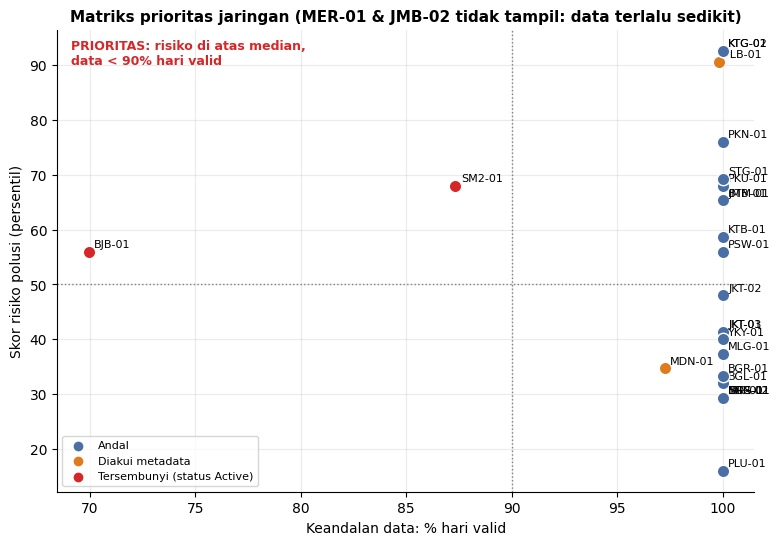

In [44]:
cov_p = sc.join(st.set_index("code")[["pulau", "gambut"]]).groupby("pulau").agg(
    stasiun=("grade", "size"), andal_AB=("grade", lambda s: s.isin(["A", "B"]).sum()),
    bermasalah=("grade", lambda s: (~s.isin(["A", "B"])).sum()))
display(cov_p)
print("Provinsi yang punya stasiun (dari sites.csv):", st.provinsi.nunique())

risk = summ[["rata2_pm25", "hari_gt150"]].join(tr[["ubah_%"]]).copy()
risk["skor_risiko"] = risk.rank(pct=True).mean(axis=1) * 100
pm_mat = risk.join(sc[["hari_valid_%", "grade", "kategori"]])
fig, ax = plt.subplots(figsize=(9, 6))
for c, r in pm_mat.iterrows():
    col = {"Andal": "#4a6fa5", "Diakui metadata": "#e07a1f", "TERSEMBUNYI (status Active)": "#d62728"}[r.kategori]
    ax.scatter(r["hari_valid_%"], r.skor_risiko, s=80, color=col, edgecolor="white", zorder=3)
    ax.annotate(c, (r["hari_valid_%"], r.skor_risiko), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.axhline(50, color="grey", ls=":", lw=1); ax.axvline(90, color="grey", ls=":", lw=1)
ax.text(0.02, 0.98, "PRIORITAS: risiko di atas median,\ndata < 90% hari valid", transform=ax.transAxes, fontsize=9, color="#d62728", va="top", fontweight="bold")
for k, c in {"Andal": "#4a6fa5", "Diakui metadata": "#e07a1f", "Tersembunyi (status Active)": "#d62728"}.items():
    ax.scatter([], [], color=c, label=k)
ax.legend(fontsize=8, loc="lower left")
ax.set_xlabel("Keandalan data: % hari valid"); ax.set_ylabel("Skor risiko polusi (persentil)")
ax.set_title("Matriks prioritas jaringan (MER-01 & JMB-02 tidak tampil: data terlalu sedikit)")
savefig("20_matriks_prioritas")

---
## 7. Angka kunci & parameter model untuk dashboard
Semua angka yang akan muncul di dashboard dan laporan disimpan di satu file (`angka_kunci.json`), dan parameter model dampak kesehatan di `model_dampak.json` untuk kalkulator simulasi di dashboard.

In [45]:
A24, A25 = A[A.tahun == 2024], A[A.tahun == 2025]
ak = {
    "periode_data": "2024-01-01 s.d. 2026-10-14",
    "stasiun_dianalisis": int(summ.shape[0]),
    "tahunan": {str(y): {"stasiun_sah": int(len(a)), "lampaui_baku_mutu_15": int(a.lampaui_PP22.sum()),
                         "belum_capai_IT1_35": int((a.rata2 > 35).sum())} for y, a in [(2024, A24), (2025, A25)]},
    "tren_1jan_14okt": {k: {"2024": round(float(v[2024]), 1), "2026": round(float(v[2026]), 1), "ubah_%": round(float(v["ubah_%"]), 1)}
                        for k, v in grp.iterrows()},
    "puncak_bulanan_gambut": {str(int(y)): round(float(r["max"]), 1) for y, r in peak.iterrows()},
    "episode_berat": {str(int(y)): {"jumlah": int(r.jumlah_episode), "total_hari": int(r.total_hari)} for y, r in eps_y.iterrows()},
    "minggu_awal_risiko_gambut": {str(k): v for k, v in mulai.items()},
    "dekomposisi_variasi_%": {k: round(float(v), 1) for k, v in dec.loc["Skala asli (µg/m³)"].items()},
    "shap_pemicu_%": {k: round(float(v), 1) for k, v in shap_g_pct.items()},
    "korelasi_lalu_lintas_pm25_JanJun": round(float(stats.spearmanr(attr.traffic_intensity_per_h, attr.pm25)[0]), 2),
    "rr_per_lipat_dua": {OUTC_LAB[o]: {"rr": round(float(np.exp(pooled[o]["b"])), 3),
                                        "ci": [round(float(np.exp(pooled[o]["b"] - 1.96 * pooled[o]["se"])), 3),
                                               round(float(np.exp(pooled[o]["b"] + 1.96 * pooled[o]["se"])), 3)]} for o in OUTC},
    "beban_2025_batas55": {r.outcome: {"kasus": round(float(r.selisih)), "persen": round(float(r["perubahan %"]), 1)}
                           for _, r in tot[tot.skenario.str.startswith("Batas 55")].iterrows()},
    "jaringan": sc["kategori"].value_counts().to_dict(),
    "pencemar_kritis_%": ok.polutan_kritis.value_counts(normalize=True).mul(100).round(1).to_dict(),
    "iku_2025": {r.code: {"IKU": round(float(r.IKU), 1), "kategori": str(r.kategori_IKU)} for _, r in iku25.iterrows()},
    "iku_vs_pm25_rho_2025": round(float(rho_iku), 2),
    "ambang": {OUTC_LAB[o]: a["T"] for o, a in AMBANG.items()},
    "sensitivitas_rentang_rr": {k: [round(float(r["min"]), 2), round(float(r["max"]), 2)] for k, r in rng.iterrows()},
}
(OUT / "angka_kunci.json").write_text(json.dumps(ak, ensure_ascii=False, indent=2), encoding="utf-8")
model_dampak = {"keterangan": "kasus_skenario = kasus_aktual * (pm_skenario/pm_aktual)^(b/ln2); b = koefisien log2 PM2.5 (hari yang sama), shrinkage empirical Bayes",
                "b_gabungan": {o: float(pooled[o]["b"]) for o in OUTC},
                "b_per_rs": {h: {o: float(v) for o, v in r.items()} for h, r in B_RS.iterrows()},
                "ambang": {"keterangan": "untuk outcome ini: faktor = exp(b_log*(log2 pm_baru - log2 pm_aktual) + b_h*(max(0,pm_baru-T) - max(0,pm_aktual-T))/100)",
                           **AMBANG}}
(OUT / "model_dampak.json").write_text(json.dumps(model_dampak, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(ak, ensure_ascii=False, indent=1))

{
 "periode_data": "2024-01-01 s.d. 2026-10-14",
 "stasiun_dianalisis": 25,
 "tahunan": {
  "2024": {
   "stasiun_sah": 24,
   "lampaui_baku_mutu_15": 21,
   "belum_capai_IT1_35": 12
  },
  "2025": {
   "stasiun_sah": 24,
   "lampaui_baku_mutu_15": 21,
   "belum_capai_IT1_35": 16
  }
 },
 "tren_1jan_14okt": {
  "Gambut": {
   "2024": 37.4,
   "2026": 75.7,
   "ubah_%": 102.5
  },
  "Non-gambut": {
   "2024": 35.5,
   "2026": 36.7,
   "ubah_%": 3.2
  }
 },
 "puncak_bulanan_gambut": {
  "2024": 69.6,
  "2025": 108.0,
  "2026": 335.6
 },
 "episode_berat": {
  "2024": {
   "jumlah": 11,
   "total_hari": 84
  },
  "2025": {
   "jumlah": 17,
   "total_hari": 89
  },
  "2026": {
   "jumlah": 20,
   "total_hari": 198
  }
 },
 "minggu_awal_risiko_gambut": {
  "2024": 32,
  "2025": 32,
  "2026": 31
 },
 "dekomposisi_variasi_%": {
  "Lokasi (antar stasiun)": 16.1,
  "Musim/episode (stasiun-bulan)": 81.6,
  "Hari ke hari": 2.2
 },
 "shap_pemicu_%": {
  "Hari dalam seminggu": 0.5,
  "Suhu": 3.7,
  

---
## 8. Q6 · Sintesis: Apakah Insight Sudah Menjawab Pertanyaan?

| # | Pertanyaan | Jawaban dari data | Status |
|---|---|---|---|
| **Q1** | Kondisi kualitas udara terhadap baku mutu, ISPU, IKU, WHO, dan trennya | **21 dari 24** stasiun dengan data sah melampaui baku mutu tahunan nasional (15 µg/m³) pada 2024 dan 2025. Stasiun yang **belum mencapai target antara WHO paling longgar (35)** naik **12 → 16**. ISPU resmi (semua parameter): **PM2.5 adalah pencemar kritis di 99,6% hari**, gas tidak pernah melewati kategori Sedang. **IKU resmi (NO₂ & SO₂) "buta asap":** 12 stasiun ber-IKU *Baik* padahal PM2.5 tahunannya > 35; hanya Jakarta yang *Kurang/Sangat Kurang*. Tren 1 Jan–14 Okt 2024→2026: **gambut +102%**, non-gambut +3%, 13 dari 24 stasiun datar. Pemburukan gambut terjadi **hanya di musim asap** (Kalteng Jul–Okt +540%, Jan–Jun datar), sedangkan **Samarinda** memburuk di luar musim asap (Jan–Jun +61%). Clustering pola waktu memisahkan **episodik** (10) dari **stabil**; dengan acuan level jadi 4 tipe: episodik, kronis (8), sedang (4), latar bersih (3) | ✅ Terjawab |
| **Q2** | Waktu & wilayah paling kritis | **Musim asap Jul–Okt** di kawasan gambut; puncak bulanan **69,6 → 108,0 → 335,6 µg/m³** (2024 → 2025 → Okt 2026). Episode berat (≥3 hari > 150): **84 → 89 → 198 hari**, terpanjang **44 hari** (Kalteng, 1 Sep–14 Okt 2026, masih berlangsung). Hari tidak sehat mulai mendominasi **minggu ke-31/32 (awal Agustus)**. Puncak harian **07–08 pagi** dan **17–19 sore** (jam lokal); ozon memuncak siang. Akhir pekan **tidak berbeda** (median 0,03%). Pola dini hari IDP-01 bukan akibat jam yang bergeser (digeser 0–23 jam tetap tidak cocok), jadi diperlakukan sebagai anomali stasiun | ✅ Terjawab |
| **Q3** | Faktor paling berpengaruh | **Musim/episode** menjelaskan **82%** variasi PM2.5 harian, **lokasi 16%**, hari-ke-hari 2%. Antar stasiun (di luar musim asap): **lalu lintas ρ = 0,78**, jarak ke jalan ρ = −0,68 (keduanya saling terkait, ρ = −0,83). Dalam stasiun (M2, R² uji 0,72): musim **71%**, kelompok kawasan × musim 14%, cuaca (suhu, kelembapan, angin) hanya **±14%** total, hari dalam seminggu 0,5%. **Arah angin tidak berpengaruh**: di 6 stasiun industri/tepi jalan, PM2.5 per arah angin hanya berbeda 0–6% | ✅ Terjawab |
| **Q4** | Dampak kesehatan, efek jeda, kerentanan | Setiap **PM2.5 berlipat dua**: ISPA balita **+56%**, asma +61%, ISPA lansia +51%, PPOK +51%, kematian **+27%**, kardiovaskular +19%. Pernapasan berbentuk **log** dan sedikit melandai di atas 150; **kardiovaskular & kematian punya ambang di 150 µg/m³** (risiko tambahan +18% dan +14% per +100 µg/m³ di atas ambang). **Efek terjadi di hari yang sama**; lag 1–3 hari dan uji plasebo ≈ 1 → **tidak ada efek tertunda**. Balita vs lansia **sama rentan** secara relatif (1,56 vs 1,51; p = 0,60), beban absolut lansia lebih besar. Hasil **stabil di 8 uji sensitivitas** (RR balita 1,47–1,61; kematian 1,21–1,40). Antar wilayah, PM2.5 rata-rata vs kasus napas per tempat tidur **ρ = 0,95** | ✅ Terjawab kuat |
| **Q5** | Kecukupan jaringan | **21 stasiun andal**, 4 bermasalah dan diakui metadata (JMB-02, MER-01, MDN-01, PLB-01), **2 bermasalah tapi tersembunyi** (BJB-01 beku 7.329 jam, SM2-01 kode error & SUSPECT sampah) padahal berstatus *Active*. KTG-01 & KTG-02 kembar (r = 1,00, beda level 0,1%); JMB-01 & JMB-02 hanya 0,9 km. Kalimantan: 2 dari 6 stasiun bermasalah, tepat di wilayah yang paling memburuk. Indikator resmi (IKU) tidak memantau PM2.5, padahal PM2.5 adalah pencemar kritis | ✅ Sebagian. ⚠️ Lokasi titik baru hanya bisa ditentukan dari data panitia (tanpa data populasi/geografis eksternal) |
| **Q6** | Rekomendasi | Lihat di bawah | ✅ Dirumuskan, siap dibingkai di dashboard |

### Rekomendasi berbasis bukti

| Untuk | Tindakan | Kapan / ambang | Bukti | Manfaat terukur (simulasi) |
|---|---|---|---|---|
| Dinkes & BPBD provinsi gambut | Siaga RS (kapasitas rawat napas & jantung, obat, tenaga) + peringatan publik | Mulai **akhir Juli**; aktifkan penuh saat PM2.5 harian > 150 (ambang lonjakan kematian & kardiovaskular) | Kalender risiko minggu 31–32; efek di hari yang sama; ambang 150 | RS-04 Palangka Raya: menekan PM2.5 musim asap 2026 ke 55 ≈ **−1.050 ISPA balita, −1.590 kasus kardiovaskular, −510 kematian** (Jul–14 Okt) |
| KLHK & Pemda gambut | Pencegahan karhutla sebelum musim kemarau | Juni–Juli | Musim menjelaskan 82% variasi; tren gambut +102% | Batas 55 di 25 RS (2025) ≈ **−5.973 ISPA balita, −6.661 ISPA lansia, −695 kematian** per tahun |
| Pemprov DKI & kota padat | Pengendalian emisi lalu lintas & industri | Jam 06–09 & 17–19 | Lalu lintas ρ = 0,78; puncak pagi-sore; Marunda 100% hari > 55; IKU Jakarta *Kurang/Sangat Kurang* | RS-02 Marunda: PM2.5 −30% ≈ **−711 ISPA balita (−14%), −197 kematian (−14%)** per tahun |
| KLHK | Tambahkan PM2.5 ke indikator kinerja kualitas udara (IKU) | Revisi indikator berikutnya | IKU *Baik* di 12 stasiun yang gagal target WHO IT-1; PM2.5 pencemar kritis 99,6% hari | — |
| Dinkes | Proteksi kelompok rentan (balita **dan** lansia) | Hari ISPU ≥ Tidak Sehat | RR balita ≈ lansia; beban lansia terbesar | — |
| KLHK (pengelola AQMS) | Perbaiki/ganti JMB-02, MER-01; audit BJB-01 & SM2-01; QC berbasis nilai (deteksi beku, sentinel), bukan hanya label | Segera | Rapor kualitas data; 2 masalah tersembunyi | — |
| KLHK | Relokasi unit redundan (JMB-02 → hinterland Muaro Jambi; salah satu KTG) ke koridor gambut yang belum terpantau | Siklus anggaran berikutnya | KTG kembar; JMB berdempetan | — |

### Keterbatasan
- **Data sintetis.** Beberapa pola adalah ciri generator data: pola waktu yang dipakai ulang antar stasiun, nilai bulanan bertangga, Jakarta tanpa tren, NO₂/SO₂ yang nyaris sama di 13 stasiun (sehingga IKU-nya sama, 82,0). Klaim dijaga pada tingkat yang wajar dan memakai bahasa asosiasi.
- **Konversi PM dari ppm (×1000)** adalah asumsi yang konsisten dengan `baseline_pm25`; sebaiknya dikonfirmasi ke panitia.
- **Permen LHK 27/2021 (IKU)** tercatat tidak berlaku di database BPK, tetapi tetap dipakai karena disebut booklet lomba.
- **Simulasi** memakai efek hari yang sama. Pernapasan memakai kurva log per RS; kardiovaskular & kematian memakai model ambang gabungan.
- **Efek di RS dengan PM2.5 hampir konstan** (Bogor, Jakarta) tidak bisa diukur dari variasi harian; estimasinya ditarik ke efek gabungan (*shrinkage*), dan beban kronisnya ditunjukkan secara ekologis.

### Status analisis
Semua butir yang sebelumnya tertunda sudah dikerjakan: ISPU lengkap & IKU (rumus diverifikasi dari dokumen resmi), model ambang untuk simulasi, 8 uji sensitivitas, analisis arah angin, dan cek pola IDP-01. Yang tersisa hanya konfirmasi faktor konversi ppm ke panitia.

**Sumber regulasi yang diverifikasi:**
- Permen LHK No. P.14/MENLHK/SETJEN/KUM.1/7/2020 tentang ISPU, Berita Negara 2020 No. 774, Lampiran I (tabel konversi) & II (kategori): https://peraturan.go.id/files/bn774-2020.pdf
- Permen LHK No. 27 Tahun 2021 tentang Indeks Kualitas Lingkungan Hidup, Lampiran (rumus IKU, hlm. 38–41): https://peraturan.bpk.go.id/Details/235366/permen-lhk-no-27-tahun-2021